# Проект по классификации типов личности

### Цели 
Цель проекта — разработать и оценить многоклассовую модель машинного обучения для определения типов личности на основе индивидуальных и поведенческих характеристик человека, а также определить возможность сокращения набора признаков без существенного снижения качества модели.
Успешным результатом проекта считается построение модели, обеспечивающей высокое качество определения типов личности на тестовых данных, а также получение обоснованного ответа на вопрос, возможно ли сократить количество используемых признаков для формирования более короткого и удобного для практического применения опросника и как такое сокращение влияет на качество предсказаний.

### Применение классификации типов личности 
Классификация типов личности может применяться в различных сферах:
* **Образование** — для адаптации методов обучения и коммуникации с учётом индивидуальных особенностей учащихся.
* **HR и рабочая среда** — для улучшения командного взаимодействия, коммуникации и понимания комфортных условий работы сотрудников.
* **Личностное развитие** — для лучшего понимания собственных особенностей, предпочтений и поведения.
* **Психология** — как дополнительный инструмент для изучения индивидуальных особенностей и особенностей взаимодействия с другими людьми.

При этом результаты классификации целесообразно использовать как дополнительную информацию, а не как окончательную характеристику человека.


## Шаг 1. Импорт необходимых библиотек 

In [1]:
import pandas as pd
import math
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score, confusion_matrix, classification_report
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.model_selection import cross_val_score
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import precision_recall_fscore_support
from sklearn.feature_selection import RFE, mutual_info_classif
from sklearn.model_selection import KFold

## Шаг 2. Загрузка набора данных в DataFrame

In [2]:
import requests

def download_dataset(url: str, filename: str) -> None:
    """Downloads a dataset from a specified URL and saves it to a file.

    Args:
        url (str): The URL from which to download the dataset.
        filename (str): The name of the file where the dataset will be saved.

    Prints:
        A message indicating whether the dataset was successfully downloaded and saved,
        or if the download failed.
    """
    response = requests.get(url)
    if response.status_code == 200:
        with open(filename, 'wb') as file:
            file.write(response.content)
        print(f"Dataset downloaded and saved as {filename}")
    else:
        print("Failed to download the dataset")

# URL of the dataset
dataset_url = "https://habsida-datascience.s3.ap-northeast-2.amazonaws.com/datasets/personality_synthetic_dataset/personality_synthetic_dataset.csv"
# Filename to save the dataset
filename = "personality_synthetic_dataset.csv"

# Download the dataset
download_dataset(dataset_url, filename)

df = pd.read_csv('personality_synthetic_dataset.csv')
# Отображение первых 5 строк 
display(df.head())
# Отображение размерности 
print(f'Размер данных: {df.shape}')

Dataset downloaded and saved as personality_synthetic_dataset.csv


,personality_type,social_energy,alone_time_preference,talkativeness,deep_reflection,group_comfort,party_liking,listening_skill,empathy,creativity,...,spontaneity,adventurousness,reading_habit,sports_interest,online_social_usage,travel_desire,gadget_usage,work_style_collaborative,decision_speed,stress_handling
0,Extrovert,6.794295,3.854670,8.725446,2.515151,7.097368,8.588762,6.774799,6.430132,6.142968,...,4.853313,8.257134,5.270555,10.000000,9.154296,4.816422,9.191711,8.313590,8.032376,7.176905
1,Ambivert,6.378988,5.731157,7.029529,7.274493,4.111199,3.258248,5.550909,3.958179,6.149457,...,6.067201,6.289347,5.753165,5.334303,4.683781,4.725666,5.956141,5.890619,3.158988,3.423577
2,Ambivert,7.459421,6.322263,3.922269,4.622261,5.343276,7.452152,9.483990,6.127654,7.032017,...,5.524244,9.238784,5.250405,3.153540,5.000338,6.139166,6.033048,5.807500,4.571003,5.647480
3,Extrovert,6.159626,3.097837,6.019093,1.965440,7.837140,10.000000,9.436733,8.949684,8.923875,...,4.327018,8.489791,5.312617,8.379936,7.601946,6.370056,5.410145,6.671781,6.600233,5.870088
4,Introvert,5.568462,6.986722,3.913240,9.926161,1.650483,0.362298,7.470387,6.756837,9.507803,...,5.187689,3.167217,7.060235,2.333388,7.771569,5.534336,5.704598,5.832968,5.813099,3.758084


Размер данных: (20000, 30)


#### Вывод
Датасет содержит 20 000 наблюдений и 30 столбцов: целевую переменную `personality_type` и 29 числовых признаков личности. Каждая строка — один человек, значения признаков лежат на шкале 0–10.

## Шаг 3. Исследовательский анализ данных (EDA)

In [3]:
# Типы данных в каждом столбце 
df.dtypes

personality_type             object
social_energy               float64
alone_time_preference       float64
talkativeness               float64
deep_reflection             float64
group_comfort               float64
party_liking                float64
listening_skill             float64
empathy                     float64
creativity                  float64
organization                float64
leadership                  float64
risk_taking                 float64
public_speaking_comfort     float64
curiosity                   float64
routine_preference          float64
excitement_seeking          float64
friendliness                float64
emotional_stability         float64
planning                    float64
spontaneity                 float64
adventurousness             float64
reading_habit               float64
sports_interest             float64
online_social_usage         float64
travel_desire               float64
gadget_usage                float64
work_style_collaborative    

#### Вывод
Целевая переменная `personality_type` строковая (категориальная), все 29 признаков имеют тип `float64`. Преобразовывать числовые признаки не нужно, а целевую переменную позже нужно закодировать числами.

In [4]:
# Проверка на наличие пропущенных значений
df.isna().sum()

personality_type            0
social_energy               0
alone_time_preference       0
talkativeness               0
deep_reflection             0
group_comfort               0
party_liking                0
listening_skill             0
empathy                     0
creativity                  0
organization                0
leadership                  0
risk_taking                 0
public_speaking_comfort     0
curiosity                   0
routine_preference          0
excitement_seeking          0
friendliness                0
emotional_stability         0
planning                    0
spontaneity                 0
adventurousness             0
reading_habit               0
sports_interest             0
online_social_usage         0
travel_desire               0
gadget_usage                0
work_style_collaborative    0
decision_speed              0
stress_handling             0
dtype: int64

#### Вывод
Пропусков нет ни в одном столбце, заполнять или удалять данные не требуется.

In [5]:
# Проверка на наличие дубликатов 
df.duplicated().sum()

np.int64(0)

#### Вывод
Полных дубликатов нет (0), все 20 000 строк уникальны.

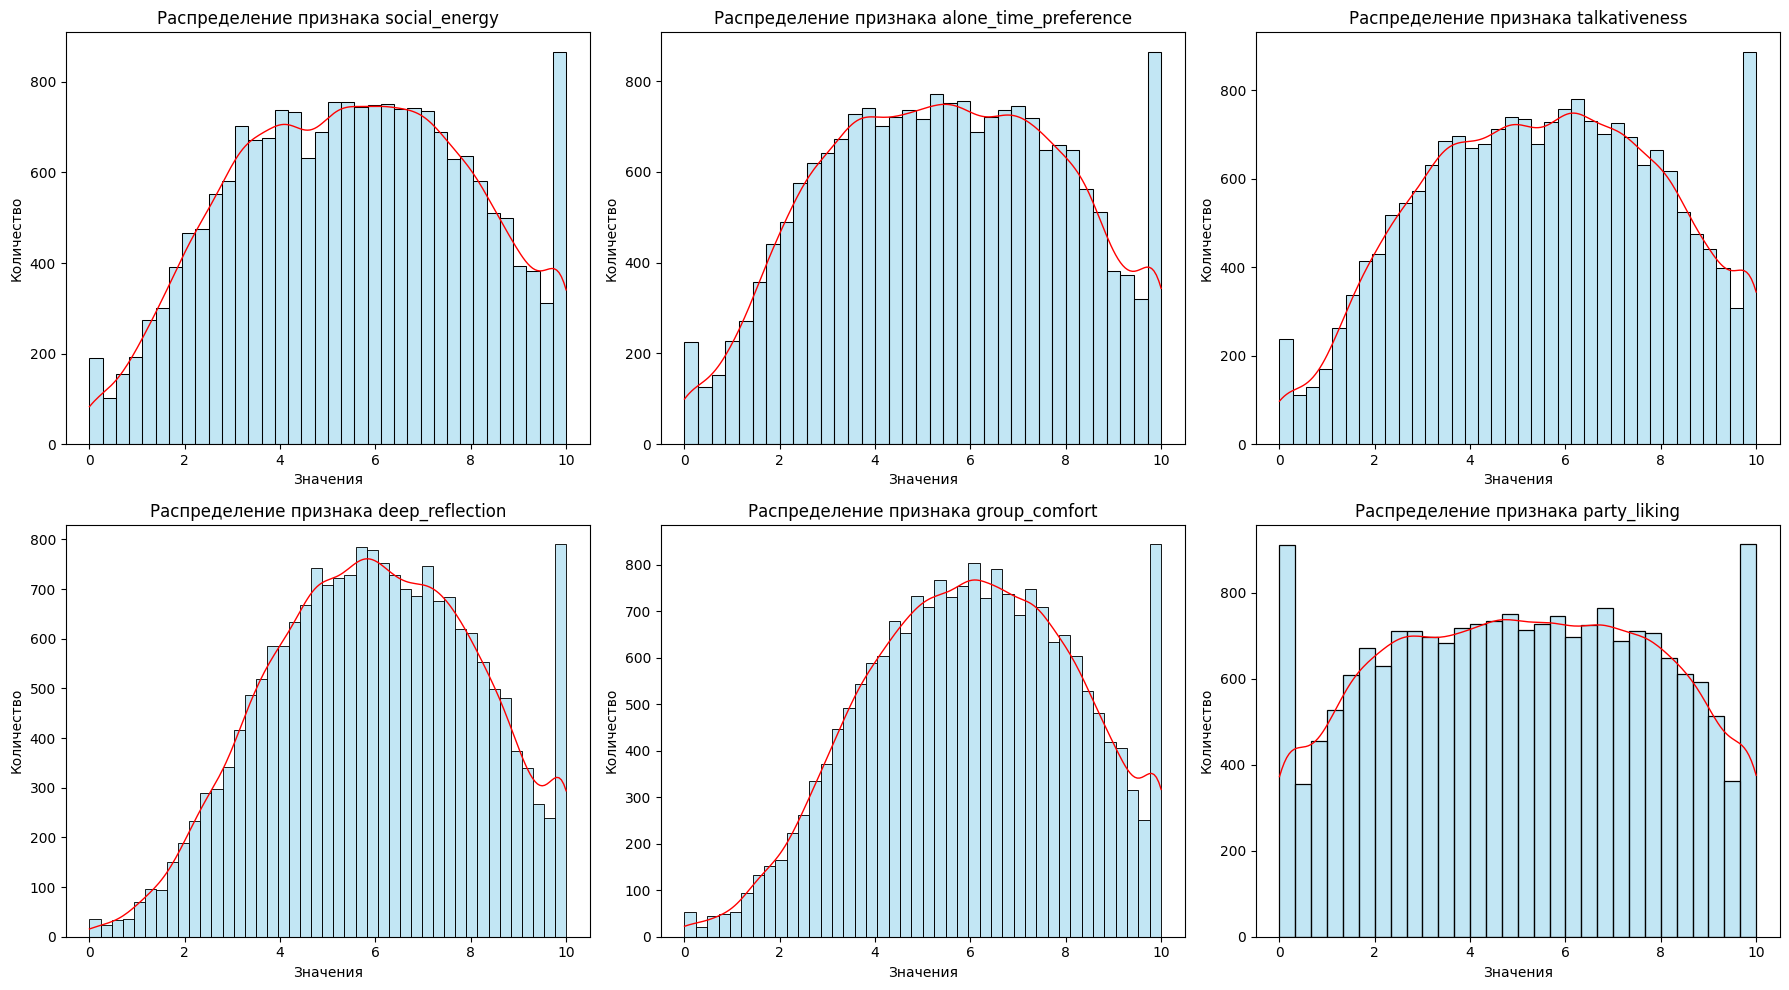

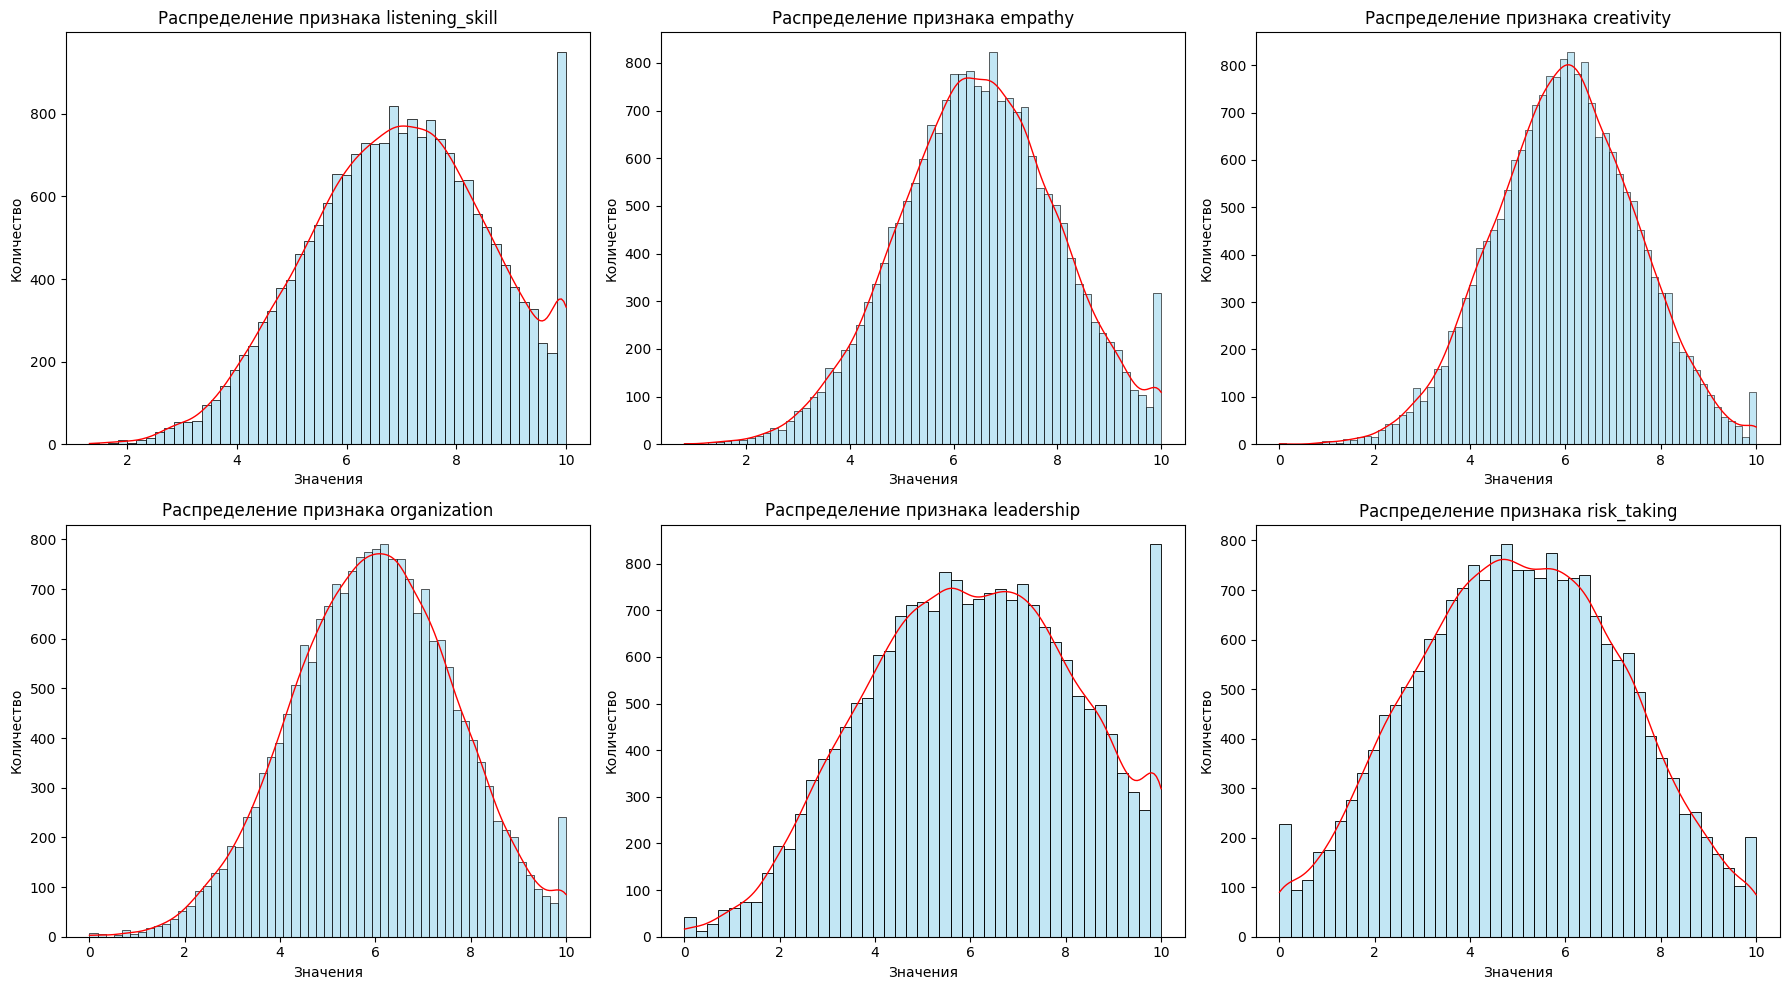

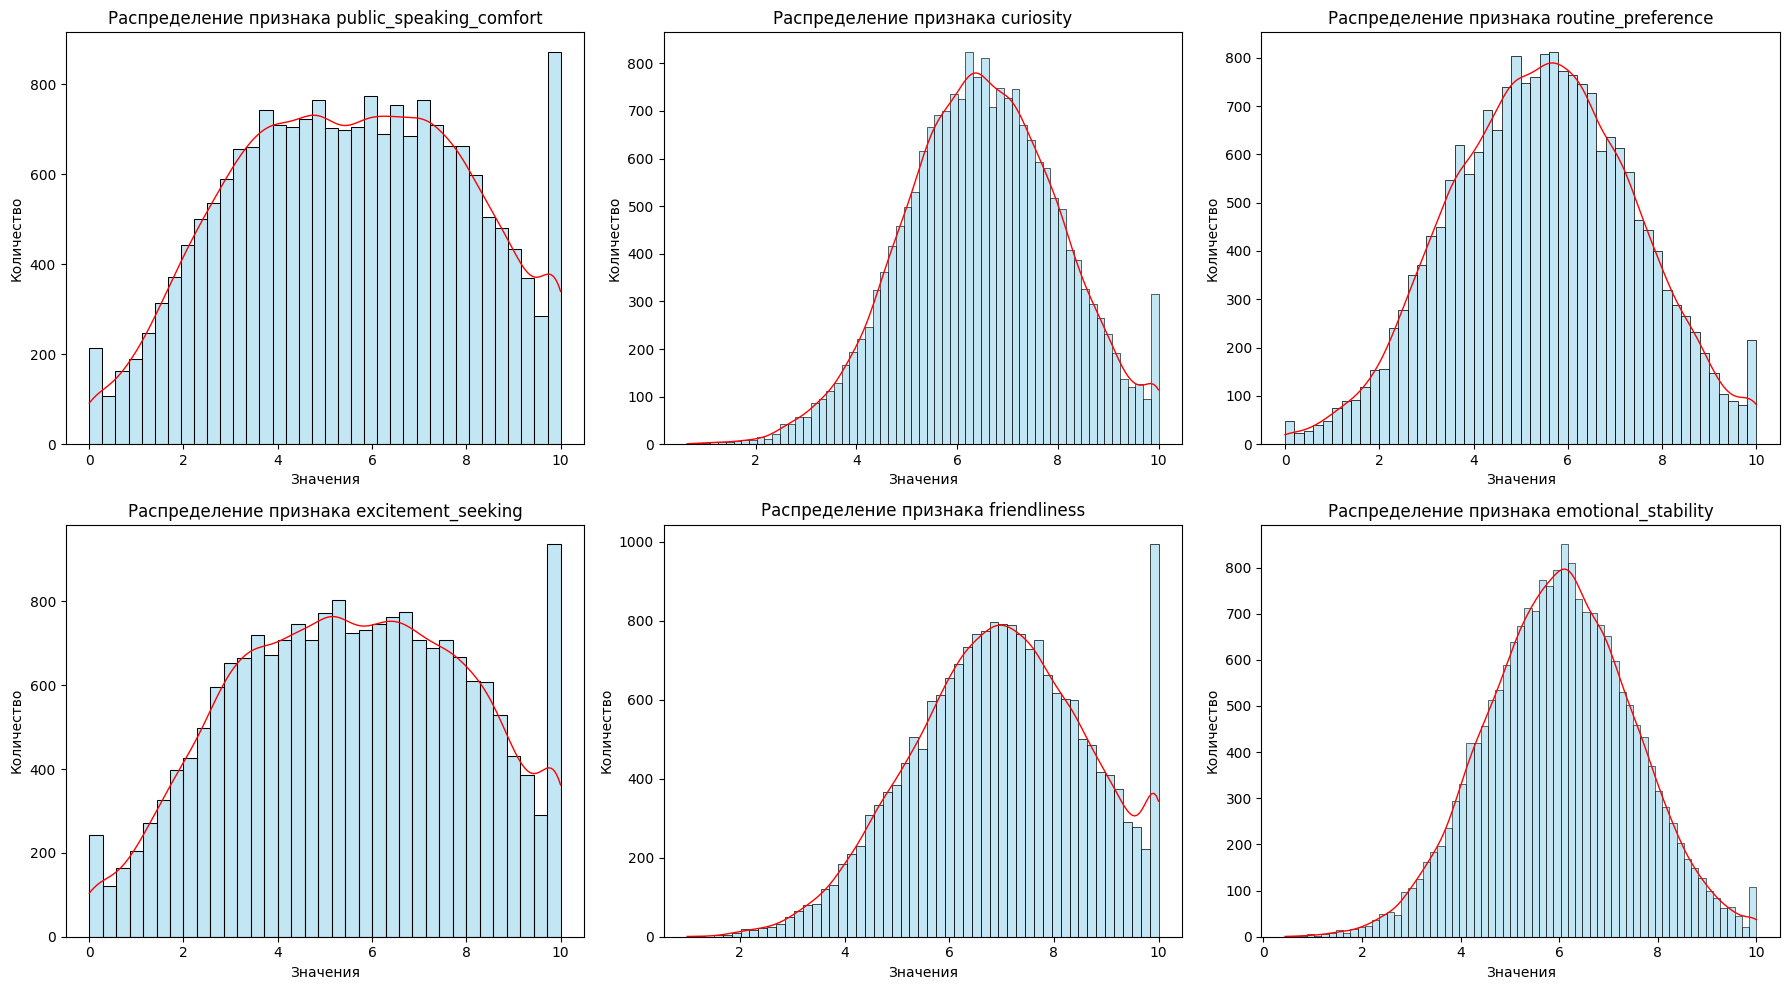

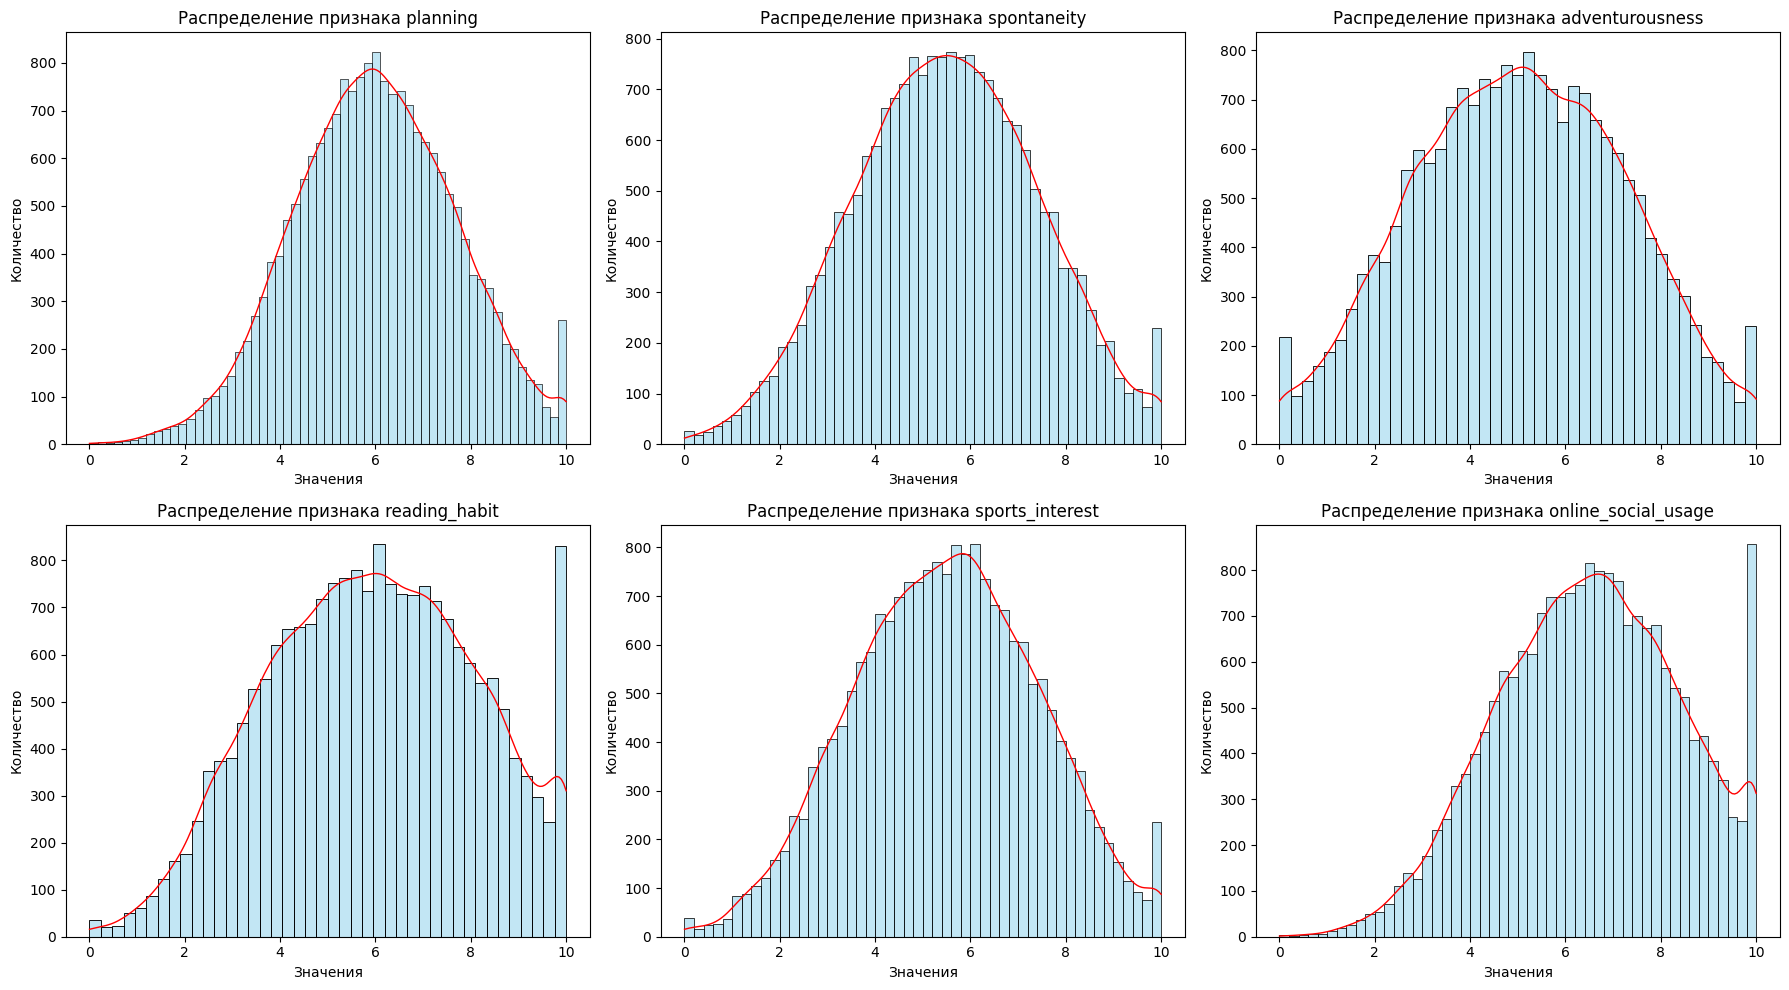

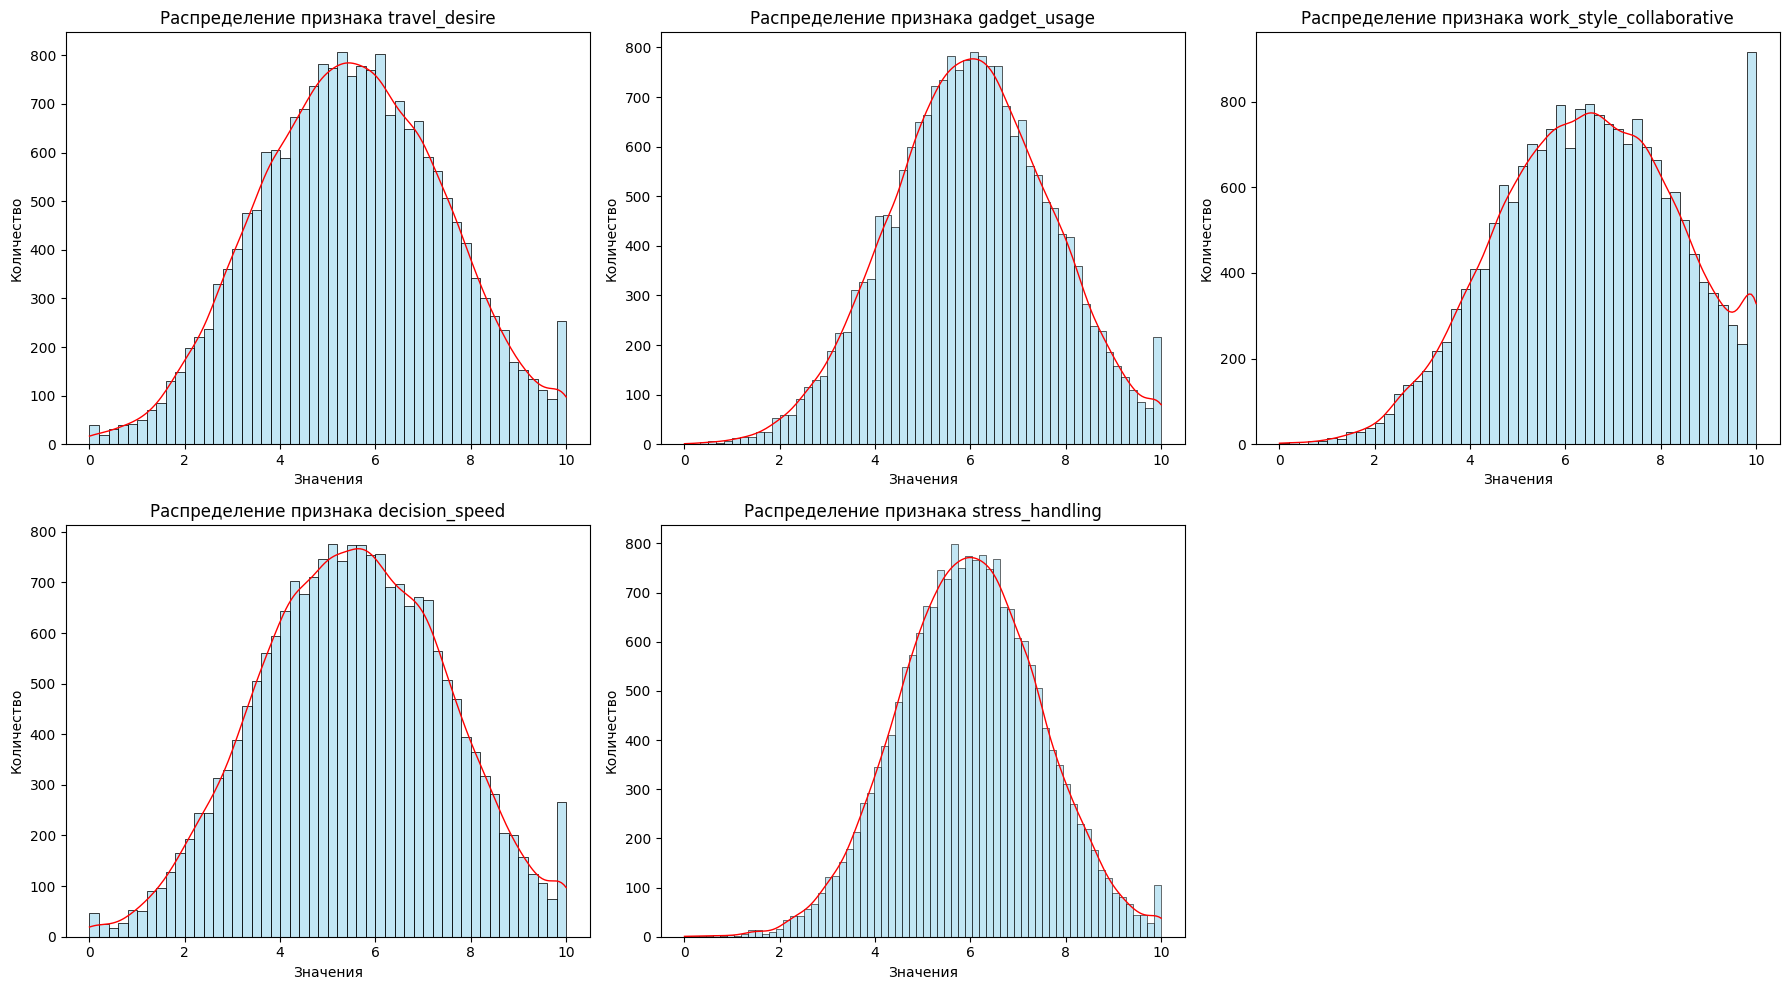

In [6]:
# Визуализация распределния каждого признака личности 
features = df.columns[1:]
per_fig = 6
n_cols = 3
n_rows = 2
n_figs = math.ceil(len(features) / per_fig)

for i in range(n_figs):
    chunk = features[i * per_fig:(i + 1) * per_fig]

    fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 10))
    axes = axes.flatten()

    for ax, feature in zip(axes, chunk):
        sns.histplot(data=df, x=feature, kde=True, ax=ax, color='skyblue')
        ax.lines[0].set_color('red')
        ax.lines[0].set_linewidth(1)
        ax.set_title(f'Распределение признака {feature}')
        ax.set_xlabel('Значения')
        ax.set_ylabel('Количество')

    for ax in axes[len(chunk):]:
        ax.set_visible(False)

    plt.tight_layout()
    fig.savefig(f'distributions_{i + 1}.png', dpi=150, bbox_inches='tight')
    plt.show()
    plt.close(fig)

#### Вывод по графикам

Все 29 признаков измерены по единой шкале 0–10 и не требуют преобразований. Форма распределений делит признаки на две группы: у «социальных» характеристик распределения широкие и почти плоские, потому что в выборке смешаны три типа личности с разными средними, а у остальных они узкие и колоколообразные. Ограничение шкалы даёт небольшие пики на краях 0 и 10.

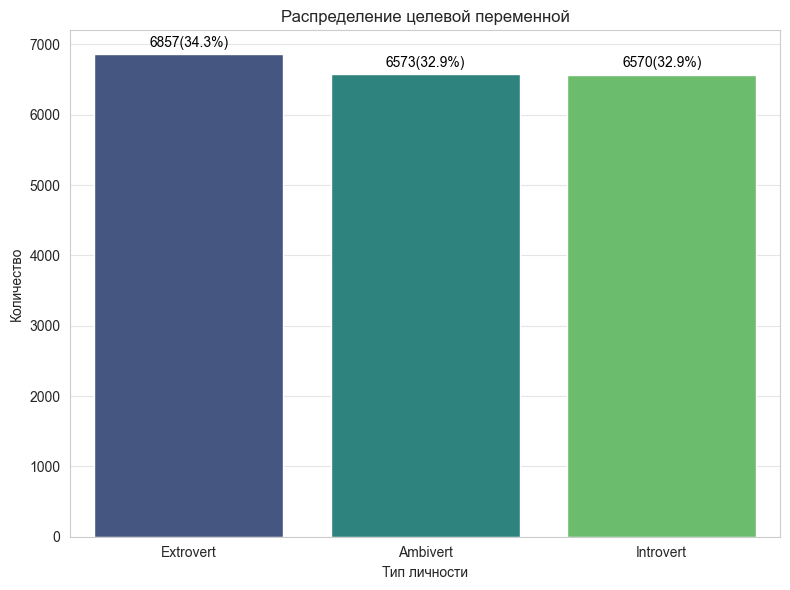

In [7]:
# Визуализация распределния целевой переменной
sns.set_style('whitegrid')
type_order = ['Introvert', 'Ambivert', 'Extrovert']
type_colors = {'Introvert': '#7FA3C7', 'Ambivert': "#64C942", 'Extrovert': '#E3B58F'}

counts = df['personality_type'].value_counts()
percentages = df['personality_type'].value_counts(normalize=True) * 100
plt.figure(figsize=(8, 6))
ax = sns.countplot(data=df, x='personality_type', hue='personality_type', palette='viridis')
for container, personality_type in zip(ax.containers, counts.index):
    count = counts[personality_type]
    percentage = percentages[personality_type]
    label = f'{count}({percentage:.1f}%)'
    ax.bar_label(container,labels=[label],label_type='edge',fontsize=10,color='black',padding=3)
plt.title('Распределение целевой переменной')
plt.xlabel('Тип личности')
plt.ylabel('Количество')
plt.tight_layout()
plt.grid(axis='y', alpha=0.5)
plt.gca().set_axisbelow(True)
plt.savefig('target_distribution.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close()

#### Вывод по графику 
Классы практически сбалансированы: Extrovert — 34.3%, Ambivert — 32.9%, Introvert — 32.9%. Разница между самым большим и самым маленьким классом около 1.4%, что несущественно. Поэтому балансировка  не нужна, а метрика accuracy информативна и не будет искажена доминированием одного класса. 

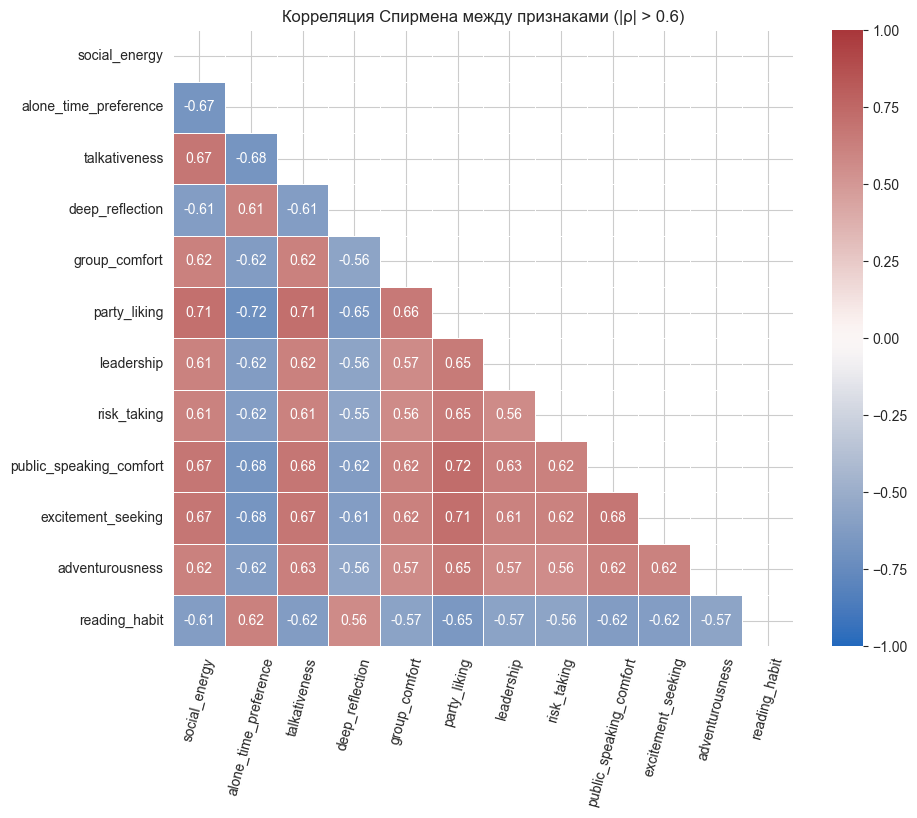

In [8]:
# Корреляционная матрица признаков (показаны признаки, у которых есть связь с |ρ| > 0.6)
corr = df[features].corr(method='spearman')
strong_features = corr.index[(corr.abs() > 0.6).sum() > 1]    # > 1, потому что диагональ всегда равна 1
corr_strong = corr.loc[strong_features, strong_features]

plt.figure(figsize=(10, 8))
sns.heatmap(corr_strong, mask=np.triu(np.ones_like(corr_strong, dtype=bool)),
            annot=True, fmt='.2f', cmap='vlag', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Корреляция Спирмена между признаками (|ρ| > 0.6)')
plt.xticks(rotation=75)
plt.savefig('correlation_matrix.png',dpi=150,bbox_inches='tight')
plt.show()
plt.close()

#### Вывод по графику
Многие признаки связаны между собой. Главная группа — «социальные» признаки: общительность, любовь к вечеринкам, социальная энергия, уверенность в публичных выступлениях и стремление к острым ощущениям. Чем выше один из них, тем выше и остальные. Стремление к одиночеству связано с ними в противоположную сторону. Связи сильные (до 0.72), но не полные: ни один признак не повторяет другой целиком. Часть признаков описывает одно и то же, поэтому опросник можно сократить, оставив по одному-два представителя группы.

In [9]:
# Вывод топ-20 признаков с наибольшей корреляцией
mask_top = np.triu(np.ones(corr.shape, dtype=bool), k=1)
strong_corr = (corr.where(mask_top).stack().loc[lambda x: x.abs() >= 0.6].sort_values(key=lambda x: x.abs(), ascending=False)).head(20)
print(strong_corr)

party_liking             public_speaking_comfort    0.719929
alone_time_preference    party_liking              -0.716237
party_liking             excitement_seeking         0.713372
talkativeness            party_liking               0.712639
social_energy            party_liking               0.710624
alone_time_preference    public_speaking_comfort   -0.679840
talkativeness            public_speaking_comfort    0.678580
public_speaking_comfort  excitement_seeking         0.678345
alone_time_preference    excitement_seeking        -0.676382
                         talkativeness             -0.675221
social_energy            talkativeness              0.674462
talkativeness            excitement_seeking         0.674110
social_energy            excitement_seeking         0.673958
                         public_speaking_comfort    0.672111
                         alone_time_preference     -0.672104
group_comfort            party_liking               0.658855
party_liking            

#### Вывод
Самые сильные связи: party_liking и public_speaking_comfort (0.72), alone_time_preference и party_liking (−0.72), party_liking и excitement_seeking (0.71), talkativeness и party_liking (0.71), social_energy и party_liking (0.71). Признак `party_liking` участвует в большинстве сильных пар, то есть это центральный признак социального кластера. Все 20 пар лежат в узком диапазоне 0.65–0.72, резких лидеров нет. Знаки корреляций согласованы: «экстравертные» признаки связаны положительно друг с другом и отрицательно с `alone_time_preference`.

In [10]:
# Сводное статистика для каждого признака личности 
df.describe()

,social_energy,alone_time_preference,talkativeness,deep_reflection,group_comfort,party_liking,listening_skill,empathy,creativity,organization,...,spontaneity,adventurousness,reading_habit,sports_interest,online_social_usage,travel_desire,gadget_usage,work_style_collaborative,decision_speed,stress_handling
count,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,...,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000,20000.000000
mean,5.509190,5.454690,5.525955,5.958689,6.014381,5.040063,6.964450,6.483220,5.996018,5.973280,...,5.495280,5.033716,5.940795,5.492490,6.498574,5.508935,6.006893,6.501986,5.516168,5.981982
std,2.468526,2.493731,2.488006,2.162427,2.178551,2.810563,1.647944,1.534911,1.496690,1.697589,...,1.922809,2.203344,2.170924,1.931728,1.889493,1.932081,1.683523,1.889782,1.944257,1.490327
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.308044,0.804853,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,3.590989,3.509578,3.595866,4.382619,4.415537,2.727584,5.812701,5.448486,4.992667,4.805742,...,4.156240,3.429189,4.325104,4.127064,5.157772,4.155375,4.867919,5.160594,4.149764,4.973047
50%,5.540706,5.464038,5.574786,5.972345,6.051489,5.053005,6.989855,6.481365,6.003320,5.986871,...,5.499699,5.045021,5.962857,5.508153,6.528960,5.498701,6.006740,6.525735,5.528102,5.978661
75%,7.424123,7.416314,7.472371,7.598495,7.668598,7.363676,8.155574,7.521483,7.013412,7.142282,...,6.853083,6.656162,7.564929,6.861487,7.885414,6.877156,7.160525,7.878841,6.905844,6.991311
max,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,...,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000,10.000000


#### Вывод
Все признаки лежат в диапазоне от 0 до 10, пропусков нет (count = 20000 везде). Средние значения большинства признаков находятся в диапазоне 5–6.5, медианы близки к средним, то есть сильной асимметрии нет. Минимальный разброс у stress_handling, creativity, empathy (std около 1.5), максимальный у party_liking (2.81), alone_time_preference, talkativeness, social_energy (около 2.5). Признаки с большим разбросом обычно сильнее различают типы.

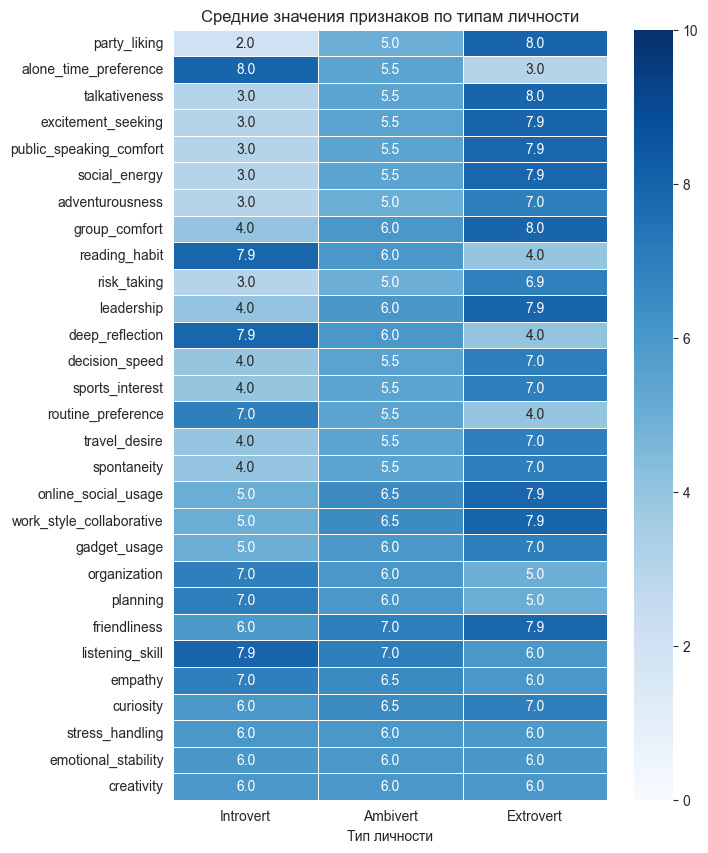

In [11]:
# Средние значения признаков по типам личности
means = df.groupby('personality_type')[features].mean().loc[type_order].T
diff = (means['Extrovert'] - means['Introvert']).abs()
means = means.loc[diff.sort_values(ascending=False).index]      # сверху признаки с самой большой разницей

plt.figure(figsize=(7, 10))
sns.heatmap(means, annot=True, fmt='.1f', cmap='Blues', vmin=0, vmax=10, linewidths=0.5)
plt.title('Средние значения признаков по типам личности')
plt.xlabel('Тип личности')
plt.ylabel('')
plt.savefig('means_by_type.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close()

#### Вывод по тепловой карте
Разница между экстравертами и интровертами достигает примерно 5 баллов по социальным признакам (вечеринки, разговорчивость, одиночество), 3–4 балла по лидерству, риску и склонности к размышлениям, 1–2 балла по эмпатии и дружелюбию и около 0 по креативности, эмоциональной стабильности и стрессоустойчивости. Амбиверт всегда посередине. Креативность, эмоциональная стабильность и стрессоустойчивость одинаковы у всех типов и не помогают их различать — это первые кандидаты на исключение из опросника.

,Introvert,Ambivert,Extrovert
party_liking,-0.75,-0.02,0.76
talkativeness,-0.71,-0.01,0.72
public_speaking_comfort,-0.71,-0.01,0.72
alone_time_preference,0.71,0.01,-0.72
excitement_seeking,-0.71,-0.01,0.71
social_energy,-0.71,-0.01,0.71
group_comfort,-0.65,-0.02,0.66
reading_habit,0.65,0.01,-0.66
leadership,-0.65,-0.01,0.65
adventurousness,-0.65,-0.01,0.65


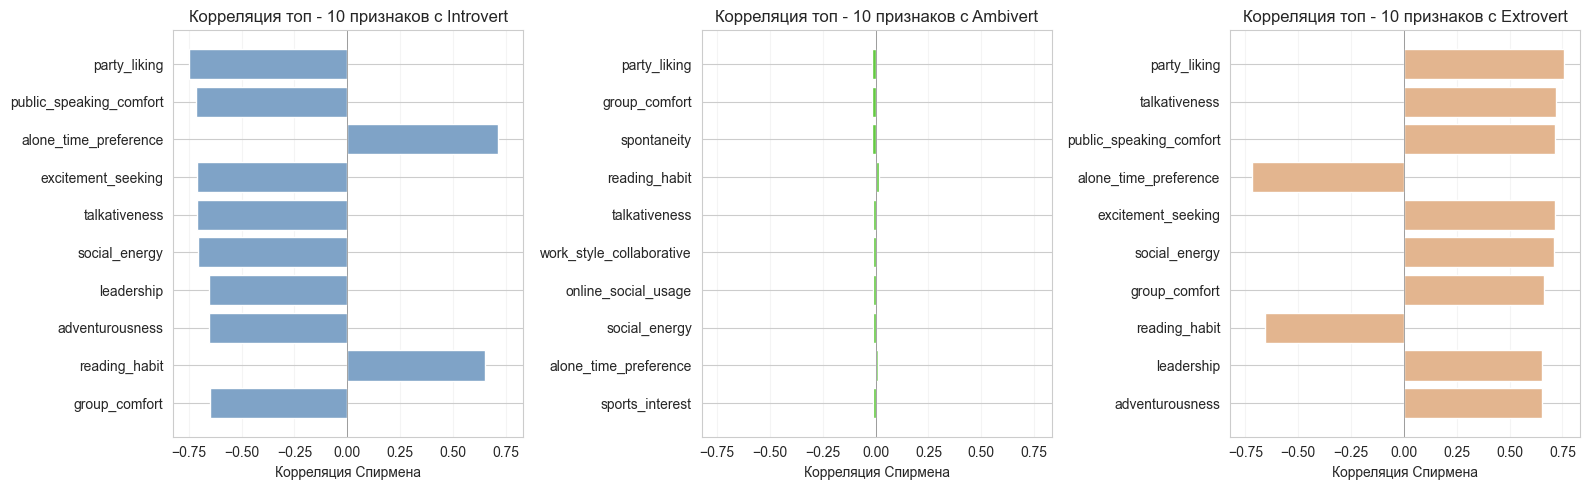

In [12]:
# Корреляция каждого признака с с типом личности
type_corr = pd.DataFrame({
    t: df[features].corrwith((df['personality_type'] == t).astype(int), method='spearman')
    for t in type_order
})
type_corr = type_corr.loc[type_corr.abs().max(axis=1).sort_values(ascending=False).index]
display(type_corr.round(2))

fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharex=True)
for ax, t in zip(axes, type_order):
    top = type_corr[t].sort_values(key=abs, ascending=False).head(10)
    ax.barh(top.index, top.values, color=type_colors[t])
    ax.invert_yaxis()
    ax.axvline(0, color='black', linewidth=0.5, alpha=0.5)
    ax.grid(axis='x', alpha=0.2)
    ax.set_title(f'Корреляция топ - 10 признаков с {t}')
    ax.set_xlabel('Корреляция Спирмена')
plt.tight_layout()
plt.savefig('feature_corr_by_type.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close()

#### Вывод по таблице и графику
Для интровертов и экстравертов набор значимых признаков почти одинаков, только знаки противоположны. У Extrovert это любовь к вечеринкам (ρ = 0.76), разговорчивость и уверенность в публичных выступлениях (0.72), острые ощущения и социальная энергия (0.71); отрицательно связаны потребность в одиночестве (−0.72) и чтение (−0.66). У Introvert те же признаки с обратным знаком. Для Ambivert корреляция со всеми признаками близка к нулю (не выше 0.02 по модулю): амбиверт имеет средние значения признаков, а линейная корреляция такое «среднее» не улавливает. Эти признаки хорошо отделяют экстравертов от интровертов, но не помогают выделить амбиверта.

#### Итоговый вывод по EDA
В данных 20 000 наблюдений и 29 признаков по шкале 0–10, пропусков и дубликатов нет, классы сбалансированы. Тип личности определяется прежде всего «социальным» блоком признаков: около 12 из 29 признаков имеют сильную связь с типом, ещё около 7 — умеренную, а три признака (креативность, эмоциональная стабильность, устойчивость к стрессу) не несут информации о типе. Между информативными признаками есть избыточность, поэтому опросник, вероятно, можно сократить. Ambivert — наименее выраженный класс, и ошибки будут возникать на его границах с остальными типами. Датасет синтетический, поэтому на реальных данных связи могут быть слабее.

## Шаг 4. Разделение данных

In [13]:
# Разделение данных на обучающую и тестовые выборки 
X = df.drop('personality_type', axis=1)
y = df['personality_type']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f'Обучающая выборка: {X_train.shape[0]}, тестовая: {X_test.shape[0]}')

Обучающая выборка: 16000, тестовая: 4000


#### Вывод
Данные разделены на обучающую (80%, 16 000 объектов) и тестовую (20%, 4 000 объектов) выборки. Отдельная валидационная выборка не нужна, потому что дальше используется кросс-валидация на обучающих данных.

## Шаг 5. Предобработка данных и построение признаков

In [14]:
# Кодирование целевой переменной
expected = LabelEncoder()
y_train = expected.fit_transform(y_train)
y_test = expected.transform(y_test)
class_names = expected.classes_
print(dict(zip(class_names, range(len(class_names)))))

{'Ambivert': 0, 'Extrovert': 1, 'Introvert': 2}


In [15]:
# Новые признаки. Их нужно строить по исходным значениям 0–10, до стандартизации
def create_features(X):
    X = X.copy()
    X['Social_Activity_Index'] = X[['party_liking', 'social_energy', 'talkativeness', 'excitement_seeking']].mean(axis=1)
    X['Social_Alone_Balance'] = X['Social_Activity_Index'] - X['alone_time_preference']
    return X

# Стандартизация: масштаб подбирается по обучающей выборке и применяется к тестовой
def scale(train, test):
    scaler = StandardScaler().fit(train)
    train_scaled = pd.DataFrame(scaler.transform(train), columns=train.columns, index=train.index)
    test_scaled = pd.DataFrame(scaler.transform(test), columns=test.columns, index=test.index)
    return train_scaled, test_scaled

# 29 исходных признаков (для моделей и PCA/LDA)
X_train, X_test = scale(X_train, X_test)
# 29 исходных + 5 новых признаков (для отбора признаков)
X_train_fe, X_test_fe = scale(create_features(X_train), create_features(X_test))

print('Исходных признаков:', X_train.shape[1], '| с новыми признаками:', X_train_fe.shape[1])

Исходных признаков: 29 | с новыми признаками: 31


#### Вывод
Создано 5 новых признаков: общий индекс социальной активности, баланс активности и времени в одиночестве. Стандартизация обучена только на обучающей выборке, поэтому информация из теста не попадает в обучение. Основные модели используют 29 исходных признаков, расширенный набор из 31 признака нужен для анализа сокращения опроса.

## Шаг 6. Обучение и оценка моделей

In [16]:
# Подбор гиперпараметров по 5-кратной кросс-валидации
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

models = {
    'Logistic Regression': (LogisticRegression(max_iter=2000, random_state=42),
                            {'C': [0.01, 0.1, 1, 10, 100]}),
    'KNN': (KNeighborsClassifier(),
            {'n_neighbors': [5, 11, 21, 31], 'weights': ['uniform', 'distance'], 'p': [1, 2]}),
    'SVC': (SVC(random_state=42),
            {'C': [0.1, 1, 10], 'kernel': ['linear', 'rbf']}),
    'Random Forest': (RandomForestClassifier(random_state=42, n_jobs=-1),
                      {'n_estimators': [200, 400], 'max_depth': [None, 10, 20], 'min_samples_leaf': [1, 3]}),
}

best_models = {}
cv_f1 = {}
for name, (model, params) in models.items():
    grid = GridSearchCV(model, params, cv=cv, scoring='f1_macro', n_jobs=-1)
    grid.fit(X_train, y_train)
    best_models[name] = grid.best_estimator_
    cv_f1[name] = grid.best_score_
    print(f'{name}: CV F1 = {grid.best_score_:.4f} | {grid.best_params_}')

Logistic Regression: CV F1 = 0.9974 | {'C': 0.01}
KNN: CV F1 = 0.9973 | {'n_neighbors': 21, 'p': 1, 'weights': 'uniform'}
SVC: CV F1 = 0.9975 | {'C': 0.1, 'kernel': 'rbf'}
Random Forest: CV F1 = 0.9954 | {'max_depth': 20, 'min_samples_leaf': 1, 'n_estimators': 200}


#### Вывод
Для всех моделей подобраны гиперпараметры, метрика — macro F1 (классы сбалансированы, и F1 одинаково учитывает все три типа). Кросс-валидация даёт очень высокое качество: 0.9974 у Logistic Regression, 0.9973 у KNN, 0.9975 у SVC и 0.9954 у Random Forest. У Logistic Regression лучший параметр `C = 0.01` лежит на краю сетки, то есть сильная регуляризация не ухудшает качество.

In [17]:
# Оценка на тестовой выборке
predictions = {name: model.predict(X_test) for name, model in best_models.items()}

rows = []
for name, y_pred in predictions.items():
    print(name)
    print(classification_report(y_test, y_pred, target_names=class_names, digits=4))
    row = {'Модель': name,
           'CV F1': cv_f1[name],
           'Accuracy': accuracy_score(y_test, y_pred),
           'Precision': precision_score(y_test, y_pred, average='macro'),
           'Recall': recall_score(y_test, y_pred, average='macro'),
           'F1': f1_score(y_test, y_pred, average='macro')}
    for cls, f1 in zip(class_names, f1_score(y_test, y_pred, average=None)):
        row[f'F1 {cls}'] = f1
    rows.append(row)

results_df = pd.DataFrame(rows).set_index('Модель').sort_values('F1', ascending=False)
display(results_df.round(4))

Logistic Regression
              precision    recall  f1-score   support

    Ambivert     0.9952    0.9968    0.9960      1261
   Extrovert     0.9993    0.9965    0.9979      1426
   Introvert     0.9977    0.9992    0.9985      1313

    accuracy                         0.9975      4000
   macro avg     0.9974    0.9975    0.9975      4000
weighted avg     0.9975    0.9975    0.9975      4000

KNN
              precision    recall  f1-score   support

    Ambivert     0.9952    0.9968    0.9960      1261
   Extrovert     0.9986    0.9979    0.9982      1426
   Introvert     0.9985    0.9977    0.9981      1313

    accuracy                         0.9975      4000
   macro avg     0.9974    0.9975    0.9975      4000
weighted avg     0.9975    0.9975    0.9975      4000

SVC
              precision    recall  f1-score   support

    Ambivert     0.9952    0.9968    0.9960      1261
   Extrovert     0.9993    0.9965    0.9979      1426
   Introvert     0.9977    0.9992    0.9985    

,CV F1,Accuracy,Precision,Recall,F1,F1 Ambivert,F1 Extrovert,F1 Introvert
Модель,,,,,,,,
Logistic Regression,0.9974,0.9975,0.9974,0.9975,0.9975,0.9960,0.9979,0.9985
SVC,0.9975,0.9975,0.9974,0.9975,0.9975,0.9960,0.9979,0.9985
KNN,0.9973,0.9975,0.9974,0.9975,0.9975,0.9960,0.9982,0.9981
Random Forest,0.9954,0.9940,0.9939,0.9940,0.9939,0.9905,0.9958,0.9954


#### Вывод
Все модели показали очень высокое качество на тесте (accuracy 0.994–0.9975). Logistic Regression, SVC и KNN достигли accuracy 0.9975, результаты Logistic Regression и SVC полностью совпали, что говорит о почти линейной разделимости классов. Random Forest слабее (accuracy 0.9940). У всех моделей самые низкие precision и recall у класса Ambivert, что согласуется с EDA: этот тип находится на границе между Introvert и Extrovert. Результаты кросс-валидации и теста почти совпадают, переобучения нет.

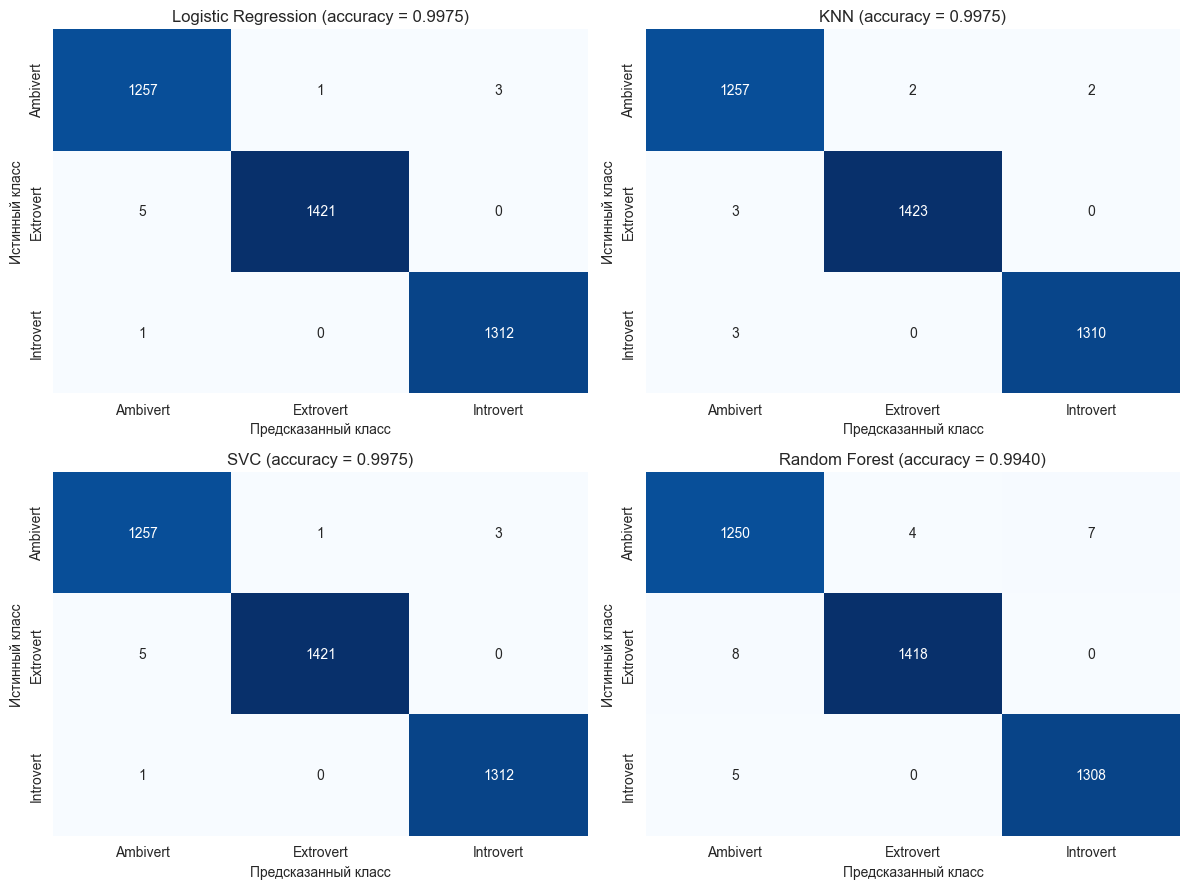

In [18]:
# Матрицы ошибок
fig, axes = plt.subplots(2, 2, figsize=(12, 9))
for ax, (name, y_pred) in zip(axes.flatten(), predictions.items()):
    sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=class_names, yticklabels=class_names, ax=ax)
    ax.set_title(f'{name} (accuracy = {accuracy_score(y_test, y_pred):.4f})')
    ax.set_xlabel('Предсказанный класс')
    ax.set_ylabel('Истинный класс')
plt.tight_layout()
plt.savefig('confusion_matrices.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close()

#### Вывод
Ошибок мало: по 10 у Logistic Regression, KNN и SVC и 24 у Random Forest. Ошибки связаны в основном с классом Ambivert (у него самые низкие precision и recall), то есть модели путают типы, которые находятся рядом на шкале, а не Introvert с Extrovert.

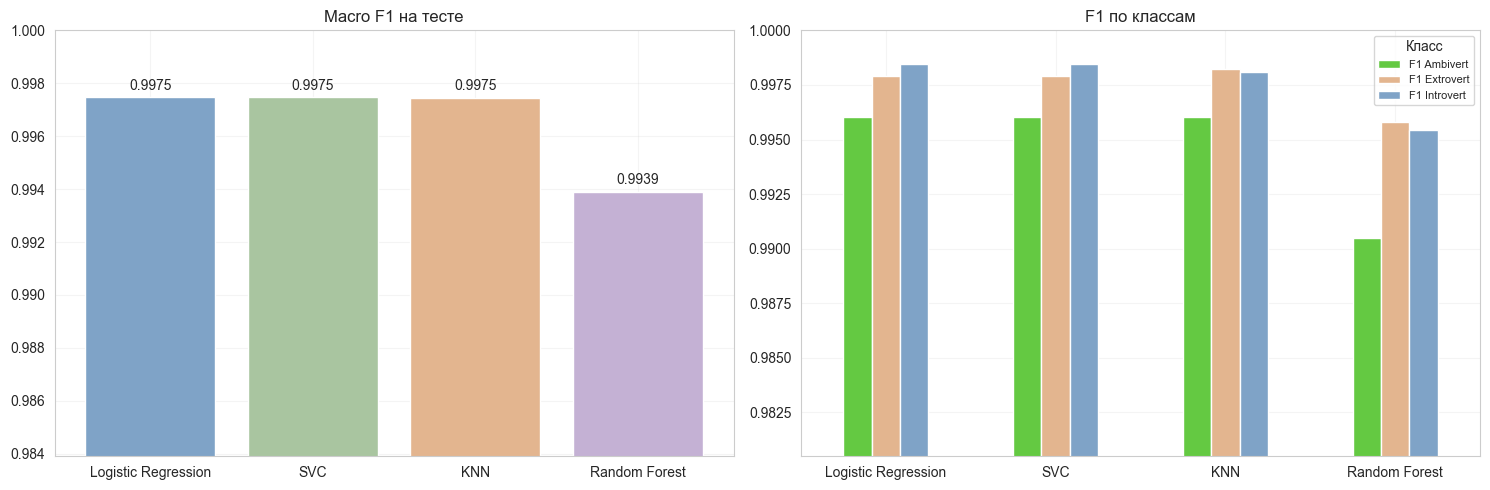

In [19]:
# Сравнение моделей
model_colors = ['#7FA3C7', '#A9C5A0', '#E3B58F', '#C4B1D4']

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

ax = axes[0]
bars = ax.bar(results_df.index, results_df['F1'], color=model_colors)
ax.bar_label(bars, fmt='%.4f', padding=3)
ax.set_ylim(results_df['F1'].min() - 0.01, 1.0)
ax.set_title('Macro F1 на тесте')
ax.tick_params(axis='x', rotation=0)
ax.grid(alpha=0.2)

f1_cols = [f'F1 {c}' for c in class_names]
results_df[f1_cols].plot(kind='bar', ax=axes[1], color=[type_colors[c] for c in class_names], edgecolor='white')
axes[1].set_ylim(results_df[f1_cols].min().min() - 0.01, 1.0)
axes[1].set_title('F1 по классам')
axes[1].set_xlabel('')
axes[1].tick_params(axis='x', rotation=0)
axes[1].legend(title='Класс', fontsize=8, title_fontsize=10)
axes[1].grid(alpha=0.2)


plt.tight_layout()
plt.savefig('models_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close()

#### Вывод
Три модели (Logistic Regression, SVC, KNN) показывают одинаковый macro F1 = 0.9975, Random Forest немного ниже (0.9939). Разница в несколько объектов не является значимой, поэтому для дальнейшей работы выбрана **Logistic Regression**: она проще, быстрее и интерпретируемее остальных. По классам лучше всего определяются Introvert и Extrovert, самый низкий F1 у Ambivert. Датасет синтетический, поэтому на реальных данных качество, вероятно, будет ниже.

In [20]:
# Три способа ранжировать признаки (на обучающей выборке, 31 признака)
feature_names = X_train_fe.columns

# 1. Фильтр: F-тест
f_scores = SelectKBest(f_classif, k='all').fit(X_train_fe, y_train).scores_
rank_filter = feature_names[np.argsort(-f_scores)]

# 2. Обертка: RFE с логистической регрессией
rfe = RFE(LogisticRegression(max_iter=2000, random_state=42), n_features_to_select=1).fit(X_train_fe, y_train)
rank_rfe = feature_names[np.argsort(rfe.ranking_)]

# 3. Встроенный метод: важность признаков Random Forest
rf = RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1).fit(X_train_fe, y_train)
rank_rf = feature_names[np.argsort(-rf.feature_importances_)]

rankings = {'Фильтр (F-тест)': rank_filter, 'Обертка (RFE)': rank_rfe, 'Встроенный (RF)': rank_rf}
display(pd.DataFrame({name: list(r[:10]) for name, r in rankings.items()}, index=range(1, 11)))

,Фильтр (F-тест),Обертка (RFE),Встроенный (RF)
1,Social_Activity_Index,Social_Activity_Index,Social_Activity_Index
2,Social_Alone_Balance,Social_Alone_Balance,Social_Alone_Balance
3,party_liking,public_speaking_comfort,party_liking
4,public_speaking_comfort,deep_reflection,public_speaking_comfort
5,alone_time_preference,adventurousness,alone_time_preference
6,talkativeness,group_comfort,excitement_seeking
7,excitement_seeking,reading_habit,talkativeness
8,social_energy,risk_taking,social_energy
9,reading_habit,leadership,reading_habit
10,group_comfort,party_liking,group_comfort


#### Вывод
Три метода ранжируют признаки по-разному: F-тест оценивает каждый признак отдельно, RFE по очереди убирает наименее полезные признаки и каждый раз переобучает модель, а Random Forest оценивает вклад признака в деревьях. В топ-10 каждого метода как правило, входят признаки социального блока (`party_liking`, `alone_time_preference`, `public_speaking_comfort` и другие) и построенные из них новые признаки.

In [21]:
# Качество каждой модели на первых k признаках каждого ранжирования (кросс-валидация)
k_values = [1, 2, 3, 4, 5, 6, 8, 10, 12, 15, 20, 25, X_train_fe.shape[1]]

baseline = {}     # CV F1 на всех 31 признаках
cv_scores = {}    # CV F1 для каждой пары (модель, метод) при разном k
for model_name, model in best_models.items():
    baseline[model_name] = cross_val_score(model, X_train_fe, y_train, cv=cv, scoring='f1_macro', n_jobs=-1).mean()
    for method, ranking in rankings.items():
        cv_scores[(model_name, method)] = [
            cross_val_score(model, X_train_fe[list(ranking[:k])], y_train, cv=cv, scoring='f1_macro', n_jobs=-1).mean()
            for k in k_values]
    print(f'{model_name}: готово')

Logistic Regression: готово
KNN: готово
SVC: готово
Random Forest: готово


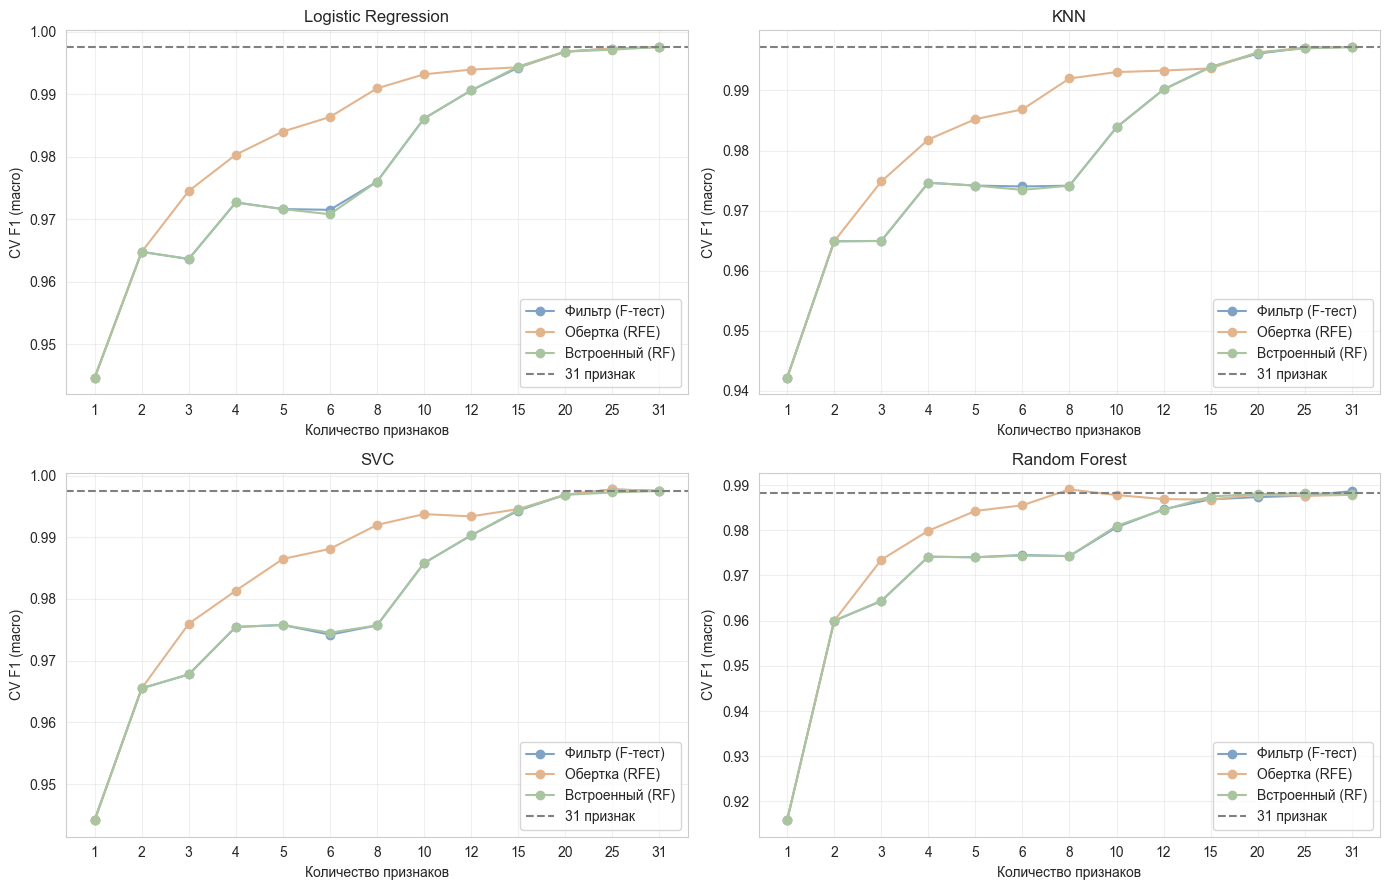

In [22]:
# Графики: как число признаков влияет на качество каждой модели
method_colors = {'Фильтр (F-тест)': '#7FA3C7', 'Обертка (RFE)': '#E3B58F', 'Встроенный (RF)': '#A9C5A0'}
x = range(len(k_values))

fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, model_name in zip(axes.flatten(), best_models):
    for method in rankings:
        ax.plot(x, cv_scores[(model_name, method)], marker='o', color=method_colors[method], label=method)
    ax.axhline(baseline[model_name], color='gray', linestyle='--', label='31 признак')
    ax.set_xticks(x)
    ax.set_xticklabels(k_values)
    ax.set_title(model_name)
    ax.set_xlabel('Количество признаков')
    ax.set_ylabel('CV F1 (macro)')
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.savefig('cv_f1_by_k.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close()

#### Вывод
На графиках видно, как меняется качество каждой модели по мере добавления признаков в порядке их важности. У всех моделей качество сначала быстро растёт, затем выходит на плато и почти совпадает с результатом на всех 31 признаке. Значит, для хорошего результата нужна только часть признаков. Модели и методы различаются тем, при каком k наступает плато: чем раньше кривая достигает пунктирной линии, тем меньше признаков нужно этой модели при этом способе ранжирования.

k   CV F1  Accuracy      F1
Модель              Метод                                        
Logistic Regression Все признаки     31  0.9976    0.9975  0.9975
                    Фильтр (F-тест)  15  0.9942    0.9945  0.9944
                    Обертка (RFE)    12  0.9939    0.9918  0.9916
                    Встроенный (RF)  15  0.9944    0.9948  0.9947
KNN                 Все признаки     31  0.9972    0.9970  0.9970
                    Фильтр (F-тест)  15  0.9939    0.9925  0.9924
                    Обертка (RFE)    12  0.9933    0.9925  0.9924
                    Встроенный (RF)  15  0.9939    0.9930  0.9929
SVC                 Все признаки     31  0.9975    0.9972  0.9972
                    Фильтр (F-тест)  15  0.9943    0.9948  0.9947
                    Обертка (RFE)    10  0.9937    0.9932  0.9932
                    Встроенный (RF)  15  0.9944    0.9948  0.9947
Random Forest       Все признаки     31  0.9884    0.9898  0.9896
                    Фильтр (F-тест)  12  0.9847    0.9852  0.9850
                    Обертка (RFE)     6  0.9855    0.9842  0.9840
                    Встроенный (RF)  12  0.9845    0.9855  0.9852

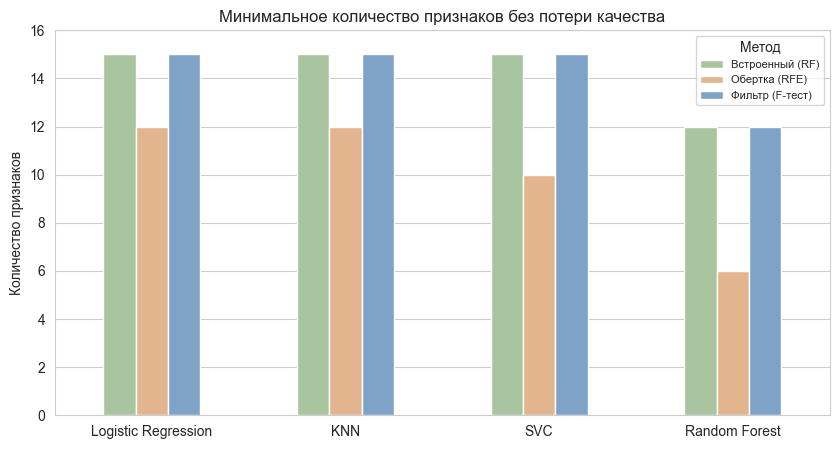

In [23]:
# Минимальное k, при котором CV F1 отличается от полного набора не больше чем на 0.004 и проверка на тесте
tol = 0.004
rows = []
selected = {}

for model_name, model in best_models.items():
    full_model = model.__class__(**model.get_params()).fit(X_train_fe, y_train)
    pred = full_model.predict(X_test_fe)
    rows.append({'Модель': model_name, 'Метод': 'Все признаки', 'k': X_train_fe.shape[1],
                 'CV F1': baseline[model_name], 'Accuracy': accuracy_score(y_test, pred),
                 'F1': f1_score(y_test, pred, average='macro')})

    for method, ranking in rankings.items():
        scores = cv_scores[(model_name, method)]
        k = next((k for k, s in zip(k_values, scores) if s >= baseline[model_name] - tol), k_values[-1])
        cols = list(ranking[:k])
        selected[(model_name, method)] = cols

        short_model = model.__class__(**model.get_params()).fit(X_train_fe[cols], y_train)
        pred = short_model.predict(X_test_fe[cols])
        rows.append({'Модель': model_name, 'Метод': method, 'k': k,
                     'CV F1': scores[k_values.index(k)], 'Accuracy': accuracy_score(y_test, pred),
                     'F1': f1_score(y_test, pred, average='macro')})

selection_df = pd.DataFrame(rows).set_index(['Модель', 'Метод'])
display(selection_df.round(4))

# Сколько признаков нужно каждой модели при каждом методе
k_table = selection_df['k'].unstack('Метод').drop(columns='Все признаки').loc[list(best_models)]
k_table.plot(kind='bar', figsize=(10, 5), color=[method_colors[m] for m in k_table.columns], edgecolor='white')
plt.title('Минимальное количество признаков без потери качества')
plt.ylabel('Количество признаков')
plt.xlabel('')
plt.xticks(rotation=0)
plt.yticks(range(0, int(k_table.max().max()) + 2, 2))
plt.grid(axis='x', visible=False)
plt.legend(title='Метод', fontsize=8, title_fontsize=10)
plt.savefig('optimal_k_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close()

In [24]:
# Сколько исходных вопросов нужно, если часть выбранных признаков — производные
derived_from = {
    'Social_Activity_Index': ['party_liking', 'social_energy', 'talkativeness', 'excitement_seeking'],
    'Social_Alone_Balance': ['party_liking', 'social_energy', 'talkativeness', 'excitement_seeking', 'alone_time_preference'],
}

for (model_name, method), cols in selected.items():
    questions = set()
    for c in cols:
        questions.update(derived_from.get(c, [c]))
    diff = selection_df.loc[(model_name, method), 'F1'] - selection_df.loc[(model_name, 'Все признаки'), 'F1']
    verdict = 'потери качества практически нет' if diff > -0.001 else 'качество немного снижается'
    print(f'{model_name} | {method}: {len(cols)} признаков, исходных вопросов {len(questions)} из 29, '
          f'F1 на тесте {diff:+.4f} к полному набору ({verdict})')

Logistic Regression | Фильтр (F-тест): 15 признаков, исходных вопросов 13 из 29, F1 на тесте -0.0031 к полному набору (качество немного снижается)
Logistic Regression | Обертка (RFE): 12 признаков, исходных вопросов 12 из 29, F1 на тесте -0.0058 к полному набору (качество немного снижается)
Logistic Regression | Встроенный (RF): 15 признаков, исходных вопросов 13 из 29, F1 на тесте -0.0028 к полному набору (качество немного снижается)
KNN | Фильтр (F-тест): 15 признаков, исходных вопросов 13 из 29, F1 на тесте -0.0046 к полному набору (качество немного снижается)
KNN | Обертка (RFE): 12 признаков, исходных вопросов 12 из 29, F1 на тесте -0.0046 к полному набору (качество немного снижается)
KNN | Встроенный (RF): 15 признаков, исходных вопросов 13 из 29, F1 на тесте -0.0041 к полному набору (качество немного снижается)
SVC | Фильтр (F-тест): 15 признаков, исходных вопросов 13 из 29, F1 на тесте -0.0026 к полному набору (качество немного снижается)
SVC | Обертка (RFE): 10 признаков, исхо

#### Вывод по сокращению опросника
Для каждой пары «модель — метод» выбрано минимальное число признаков, при котором кросс-валидационный F1 не хуже полного набора больше чем на 0.004. Тестовая выборка содержит 4000 объектов, поэтому один объект меняет accuracy на 0.00025, а различия меньше примерно 0.001 (около 4 объектов) нельзя считать значимыми; именно по этому порогу в выводе выше стоит пометка «потери качества практически нет». Из таблицы и столбчатой диаграммы видно, какой модели и какому методу нужно меньше всего признаков: чем ниже столбец, тем короче можно сделать опросник. Последняя цифра в каждой строке вывода показывает, сколько исходных вопросов нужно на самом деле, потому что часть выбранных признаков — производные от исходных. Ограничения: ранжирование признаков и выбор k делались на одной и той же обучающей выборке, поэтому кросс-валидационные оценки немного оптимистичны, а датасет синтетический.

## Шаг 7. Продвинутый анализ

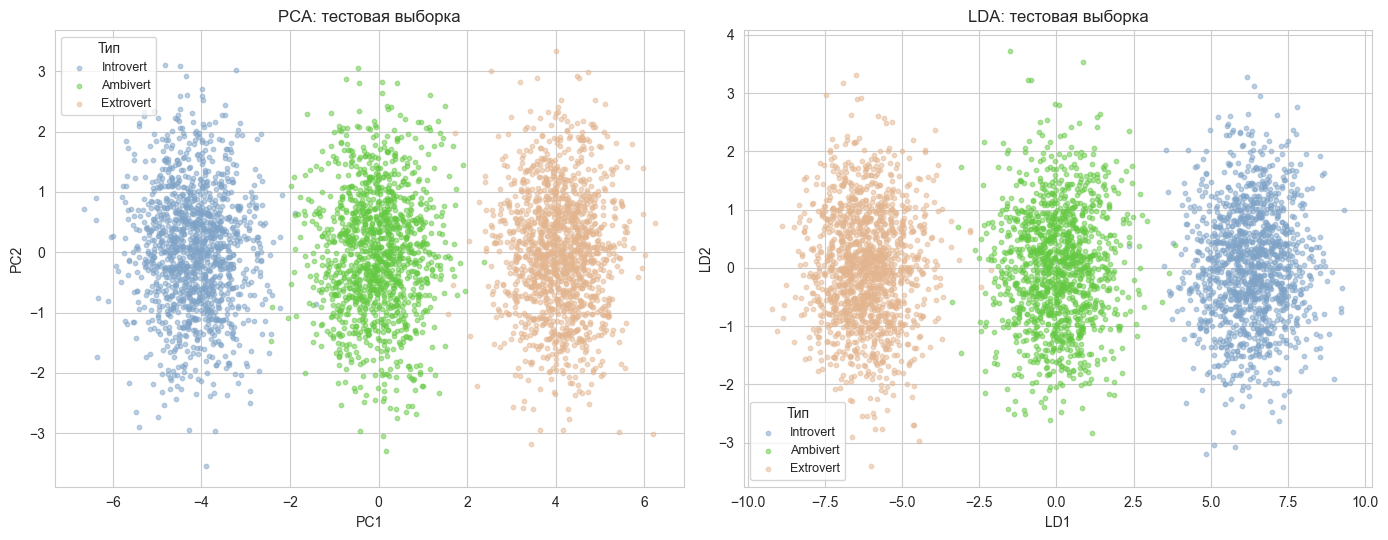

PCA: accuracy классификатора на двух компонентах = 0.9975
LDA: accuracy классификатора на двух компонентах = 0.9972


In [25]:
labels_test = class_names[y_test]          # названия типов для тестовой выборки

# PCA и LDA на 29 признаках
pca = PCA(n_components=2).fit(X_train)
lda = LDA(n_components=2).fit(X_train, y_train)
Z_pca = pca.transform(X_test)
Z_lda = lda.transform(X_test)

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
for ax, Z, name, labels in [(axes[0], Z_pca, 'PCA', ('PC1', 'PC2')), (axes[1], Z_lda, 'LDA', ('LD1', 'LD2'))]:
    for t in type_order:
        mask = labels_test == t
        ax.scatter(Z[mask, 0], Z[mask, 1], s=10, alpha=0.5, color=type_colors[t], label=t)
    ax.set_title(f'{name}: тестовая выборка')
    ax.set_xlabel(labels[0])
    ax.set_ylabel(labels[1])
    ax.legend(title='Тип', fontsize=9, title_fontsize=10)
plt.tight_layout()
plt.savefig('pca_lda_projection.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close()

for name, Z_train, Z_test in [('PCA', pca.transform(X_train), Z_pca), ('LDA', lda.transform(X_train), Z_lda)]:
    clf = LogisticRegression(max_iter=1000).fit(Z_train, y_train)
    print(f'{name}: accuracy классификатора на двух компонентах = {accuracy_score(y_test, clf.predict(Z_test)):.4f}')

#### Вывод по PCA и LDA
Оба метода сжимают 29 признаков до двух осей, но делают это по-разному. На графике PCA типы Introvert и Extrovert расходятся по первой компоненте, потому что именно «социальный» блок признаков задаёт основную дисперсию данных; Ambivert находится между ними и частично перекрывается с обоими. LDA использует метки классов, поэтому разделение на её графике чётче, а основная часть межклассовой дисперсии приходится на первую ось LD1 — в этом смысле типы личности в данных расположены на одной шкале «интроверсия — амбиверсия — экстраверсия». Числа accuracy в выводе выше показывают, насколько хорошо типы различимы всего по двум компонентам: как правило, LDA не хуже PCA, так как оптимизирует именно разделение классов. Основная причина ошибок моделей видна на обоих графиках: области Ambivert граничат с Introvert и Extrovert.

Introvert: F1 при распознавании «тип против остальных» = 0.9962
Ambivert: F1 при распознавании «тип против остальных» = 0.9885
Extrovert: F1 при распознавании «тип против остальных» = 0.9968


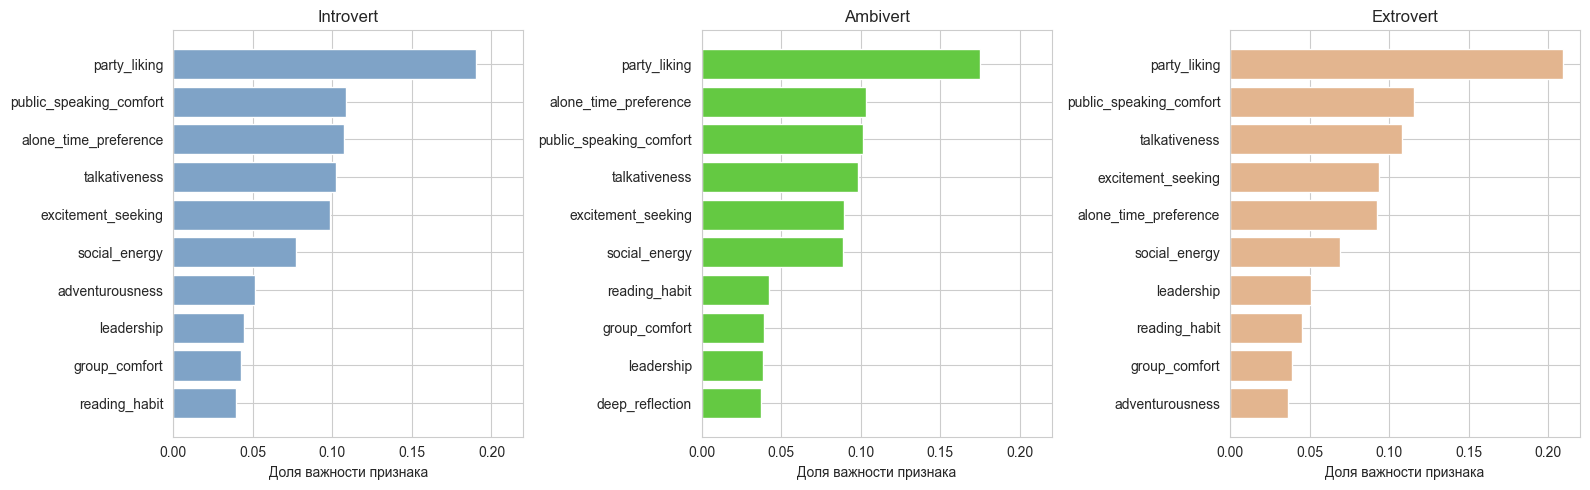

In [26]:
# Для каждого типа обучаем отдельный Random Forest на бинарной задаче «этот тип или все остальные»,
# чтобы получить важность признаков отдельно для каждого типа
importance = pd.DataFrame(index=X_train.columns)
for t in type_order:
    rf_t = RandomForestClassifier(n_estimators=200, random_state=42, n_jobs=-1)
    rf_t.fit(X_train, class_names[y_train] == t)
    importance[t] = rf_t.feature_importances_
    f1_t = f1_score(labels_test == t, rf_t.predict(X_test))
    print(f'{t}: F1 при распознавании «тип против остальных» = {f1_t:.4f}')

fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharex=True)
for ax, t in zip(axes, type_order):
    top = importance[t].sort_values(ascending=False).head(10)
    ax.barh(top.index, top.values, color=type_colors[t])
    ax.invert_yaxis()
    ax.set_title(t)
    ax.set_xlabel('Доля важности признака')
plt.tight_layout()
plt.savefig('feature_importance_by_type.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close()

#### Вывод по важности признаков
Для Introvert и Extrovert важнее всего признаки социального блока: любовь к вечеринкам, потребность в одиночестве, уверенность в публичных выступлениях, разговорчивость, социальная энергия и стремление к острым ощущениям. Списки у этих двух типов практически совпадают, так как это две стороны одной шкалы. Для Ambivert важность распределена иначе: этот тип определяется не высоким или низким значением признака, а «средним» уровнем, поэтому его труднее выделить, и F1 в выводе выше у него самый низкий среди трёх типов. Важность в Random Forest делится между коррелирующими признаками, поэтому отдельный признак из социального блока может выглядеть менее важным, чем он есть на самом деле; признаки вне социального блока (креативность, эмоциональная стабильность, стрессоустойчивость) на графиках не появляются.

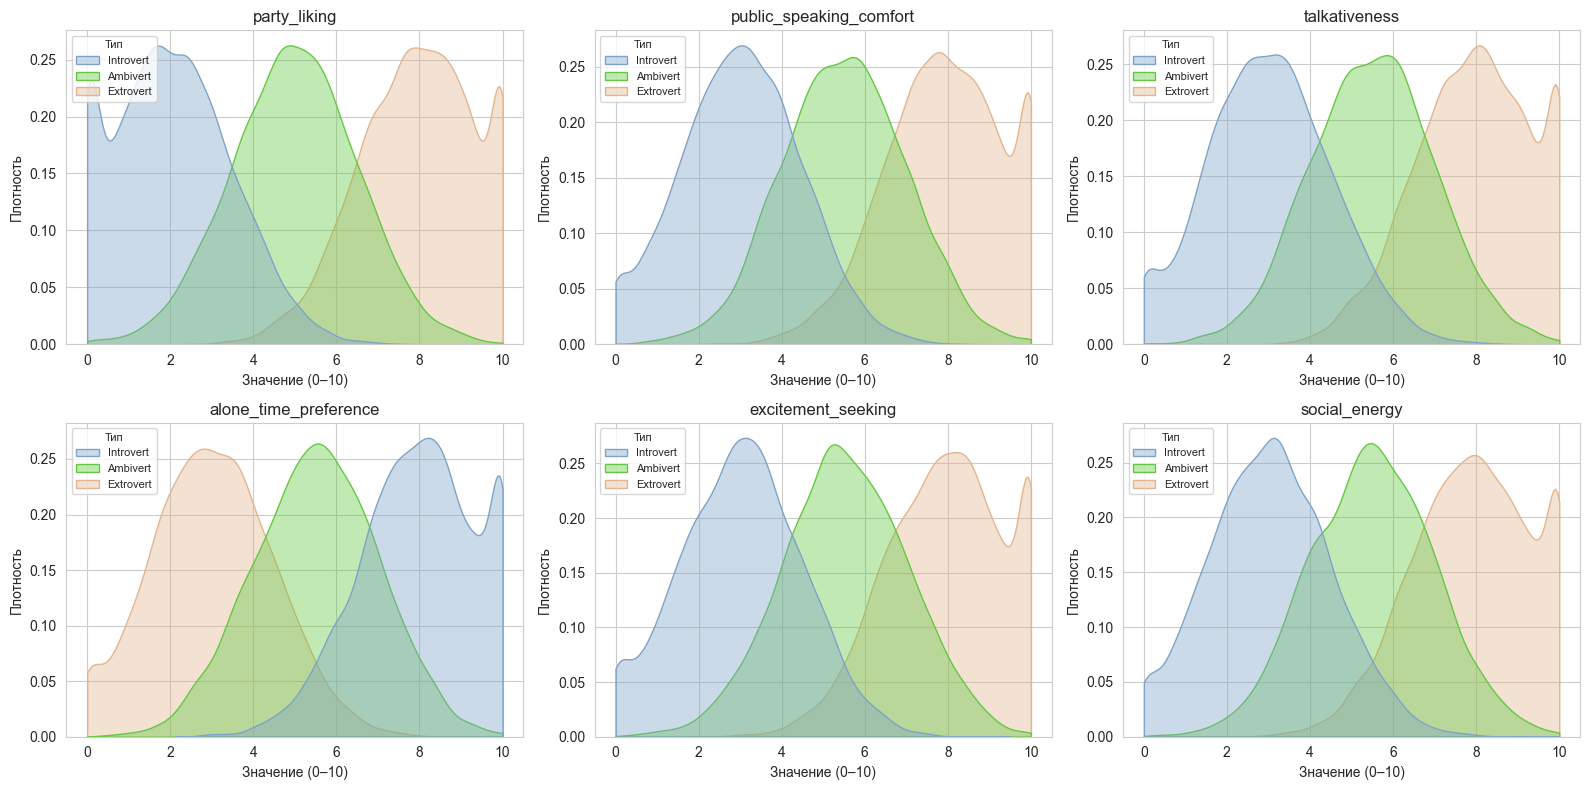

In [27]:
# Распределение шести самых важных признаков по типам
top6 = importance.mean(axis=1).sort_values(ascending=False).head(6).index

fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, feature in zip(axes.flatten(), top6):
    sns.kdeplot(data=df, x=feature, hue='personality_type', hue_order=type_order, palette=type_colors,
                fill=True, alpha=0.4, common_norm=False, clip=(0, 10), ax=ax)
    sns.move_legend(ax, 'upper left', title='Тип', fontsize=8, title_fontsize=8)   
    ax.set_title(feature)
    ax.set_xlabel('Значение (0–10)')
    ax.set_ylabel('Плотность')
plt.tight_layout()
plt.savefig('top6_feature_distributions.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close()

#### Вывод по группировке типов
По самым важным признакам кривые Introvert и Extrovert сдвинуты в противоположные стороны и пересекаются мало, а кривая Ambivert лежит посередине и перекрывается с обеими. Таблица средних подтверждает это: у Ambivert среднее значение каждого признака находится между средними Introvert и Extrovert. Ни один признак по отдельности не разделяет три типа полностью, но вместе эти признаки задают чёткую границу между крайними типами. Область перекрытия кривых и есть источник ошибок классификации.

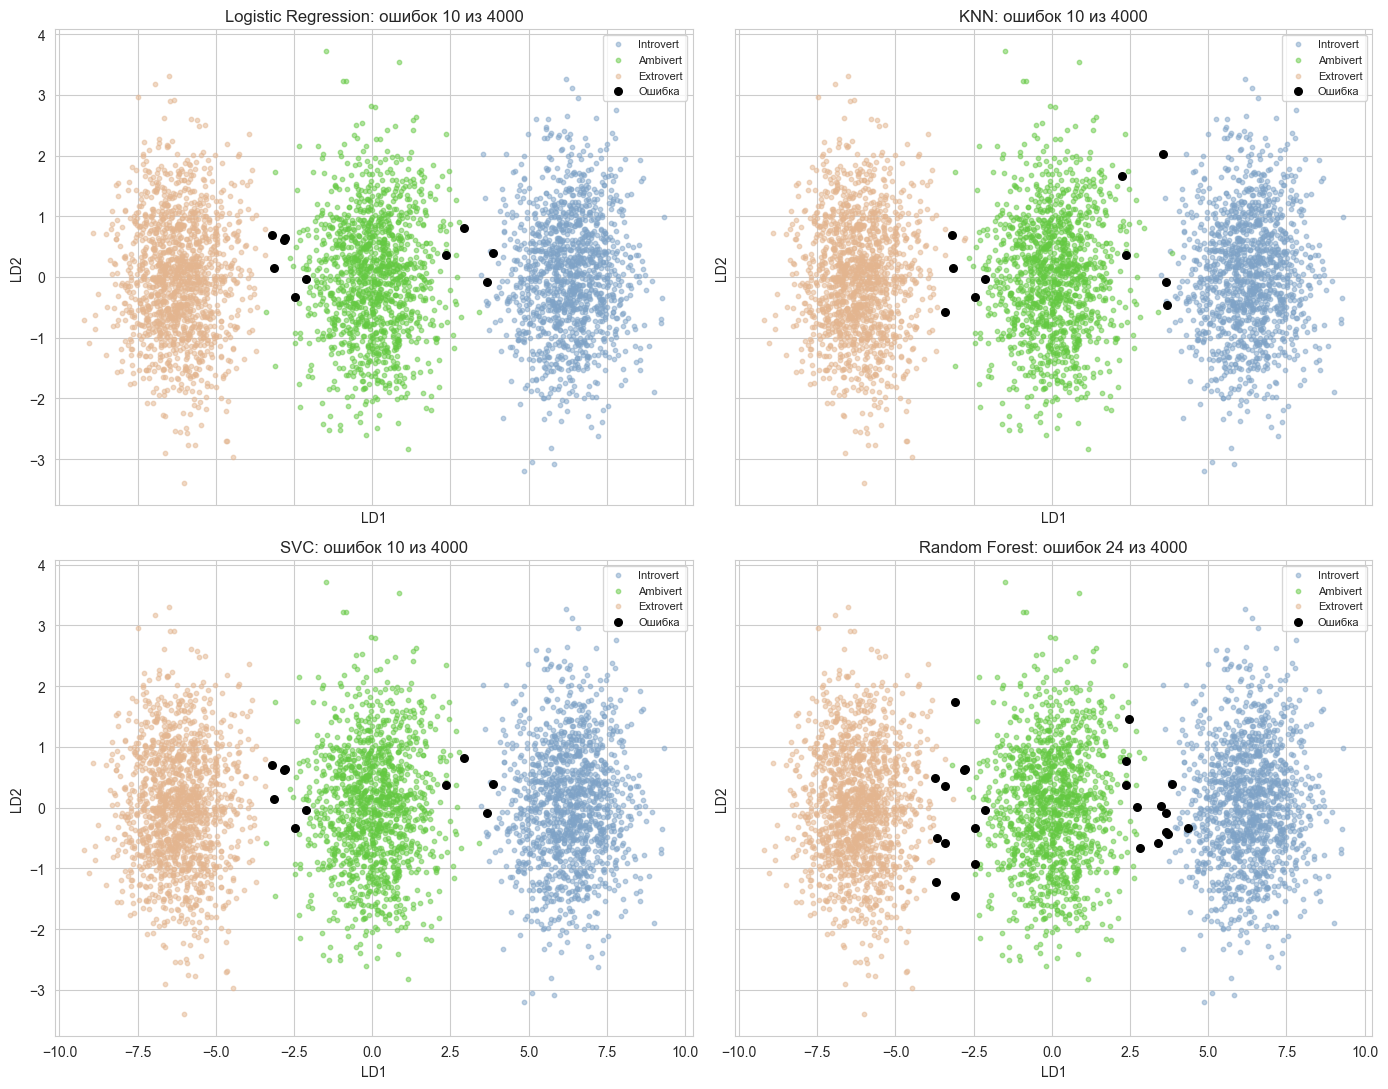

In [28]:
# Ошибки всех моделей на тесте
wrong_by_model = pd.DataFrame({name: y_pred != y_test for name, y_pred in predictions.items()}, index=X_test.index)
n_wrong = wrong_by_model.sum(axis=1)        

# Ошибки каждой модели в пространстве LDA: цвет — истинный тип, чёрные точки — ошибки
fig, axes = plt.subplots(2, 2, figsize=(14, 11), sharex=True, sharey=True)
for ax, (name, y_pred) in zip(axes.flatten(), predictions.items()):
    wrong = y_pred != y_test
    for t in type_order:
        mask = labels_test == t
        ax.scatter(Z_lda[mask, 0], Z_lda[mask, 1], s=10, alpha=0.5, color=type_colors[t], label=t)
    ax.scatter(Z_lda[wrong, 0], Z_lda[wrong, 1], s=30, color='black', label='Ошибка')
    ax.set_title(f'{name}: ошибок {wrong.sum()} из {len(y_test)}')
    ax.set_xlabel('LD1')
    ax.set_ylabel('LD2')
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig('lda_errors_by_model.png', dpi=150, bbox_inches='tight')
plt.show()
plt.close()

#### Вывод по графику

На графике все объекты тестовой выборки (4000 точек) показаны в пространстве LDA. Цвет точки — истинный тип, чёрные точки — ошибки модели.
Ошибки у всех моделей лежат только в двух узких зонах между облаками: на стыке Extrovert и Ambivert и на стыке Ambivert и Introvert. В центрах облаков и на крайних краях ошибок нет. Между Extrovert и Introvert ошибок тоже практически нет, потому что эти облака разделены широким промежутком. Почти все ошибки связаны с Ambivert: это переходный тип, и его границы с соседними типами условны.
Отличие моделей:
Logistic Regression и SVC. По 10 ошибок из 4000 (0.25%). Чёрные точки у них расположены одинаково, то есть эти модели ошибаются на одних и тех же объектах.
KNN. Тоже 10 ошибок, но набор частично другой: несколько ошибок лежат выше по LD2, чем у линейных моделей. KNN решает по ближайшим соседям, поэтому чувствительнее к локальному шуму в пограничной зоне.
Random Forest. Самый плохой результат, 24 ошибки (0.6%). Ошибки шире разбросаны вокруг обоих стыков и глубже заходят в облако Ambivert. Деревья строят границу ступенчато, а граница между типами в данных близка к линейной, поэтому лес ошибается чаще.
Все четыре модели ошибаются только в пограничной области. Объекты в зазоре между облаками действительно похожи сразу на два типа. 
Ограничение: график показывает двумерную проекцию 29-мерного пространства, поэтому на нём ошибочная точка может выглядеть «внутри чужой группы», хотя в полном пространстве она отделима. Кроме того, датасет синтетический, и на реальных данных пограничных объектов, скорее всего, будет больше.

## Итоговый вывод по проекту
1. **Данные.** 20 000 синтетических наблюдений, 29 признаков по шкале 0–10, без пропусков и дубликатов, классы сбалансированы. Тип личности определяется прежде всего «социальным» блоком признаков.
2. **Модели.** Logistic Regression, SVC и KNN дают accuracy и macro F1 = 0.9975 (10 ошибок на 4000 объектов), Random Forest — 0.9940 (24 ошибки). Классы почти линейно разделимы.
3. **Сокращение опросника.** У всех четырёх моделей качество выходит на плато при числе признаков, меньшем 34. Сколько именно признаков и исходных вопросов нужно каждой модели, показано в таблице и диаграмме раздела 6.1.
4. **Визуализация.** PCA и LDA показывают, что типы расположены на одной шкале: Introvert и Extrovert на концах, Ambivert посередине.
5. **Ошибки.** Модель ошибается в основном на границах Ambivert с соседними типами и менее уверена в таких ответах.
6. **Ограничение.** Датасет синтетический: на реальных данных качество, скорее всего, будет ниже, а результат классификации следует использовать как дополнительную информацию, а не как окончательную характеристику человека.